# Obtaining raw data

In [ ]:
if 'PROJECT_DIR' not in globals():
    from google.colab import drive
    drive.mount('/content/drive')

    from pathlib import Path

    PROJECT_DIR = Path(
        "/content/drive/MyDrive/PM25_Prediction"
    )

    print("Project folder ready:", PROJECT_DIR)
else:
    print("Project folder already established at:", PROJECT_DIR)

Project folder already established at: /content/drive/MyDrive/PM25_Prediction


Create folder for the dataset

In [ ]:
folders = [
    "data/raw",
    "data/processed",
    "notebooks",
    "models",
    "experiments",
    "figures"
]

# Check if any of the folders are missing
missing_folders = [f for f in folders if not (PROJECT_DIR / f).exists()]

if missing_folders:
    for folder in missing_folders:
        (PROJECT_DIR / folder).mkdir(
            parents=True,
            exist_ok=True
        )
    print("Created folder:", missing_folders)

print("Project folder ready:", PROJECT_DIR)

Project folder ready: /content/drive/MyDrive/PM25_Prediction


Download weather data

In [ ]:
import requests
import pandas as pd

url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": 13.729852,
    "longitude": 100.536501,
    "start_date": "2021-04-30",
    "end_date": "2026-10-31",
    "daily": [
        "temperature_2m_mean",
        "relative_humidity_2m_mean",
        "wind_speed_10m_mean",
        "precipitation_sum"
    ],
    "timezone": "Asia/Bangkok"
}

response = requests.get(
    url,
    params=params,
    timeout=60
)
response.raise_for_status()

data = response.json()
weather_df = pd.DataFrame(data["daily"])

print(weather_df.head())
print(weather_df.shape)
print(weather_df.isnull().sum())

In [ ]:
weather_df["time"] = pd.to_datetime(weather_df["time"])

assert not weather_df["time"].duplicated().any()
assert weather_df["time"].is_monotonic_increasing

output_path = PROJECT_DIR / "data/raw/weather_data_2021-2026.csv"

weather_df.to_csv(output_path, index=False)

print("Saved to:", output_path)

Download PM2.5 data

In [ ]:
import requests
from google.colab import userdata

API_KEY = userdata.get("OPENAQ_API_KEY")

BASE_URL = "https://api.openaq.org/v3"
HEADERS = {"X-API-Key": API_KEY}

response = requests.get(
    f"{BASE_URL}/locations/5545/sensors",
    headers=HEADERS,
    timeout=30
)
response.raise_for_status()

sensors = response.json()["results"]

for sensor in sensors:
    print(
        "Sensor ID:", sensor["id"],
        "| Parameter:", sensor["parameter"]["name"],
        "| Unit:", sensor["parameter"]["units"]
    )

In [ ]:
import pandas as pd
import time

pm25_sensors = [
    s for s in sensors
    if s["parameter"]["name"].lower() == "pm25"
]

assert pm25_sensors, "No PM2.5 sensor found"

# Start with the first PM2.5 sensor.
# Check for additional sensors before finalizing the dataset.
SENSOR_ID = pm25_sensors[0]["id"]

all_records = []
page = 1

while True:
    response = requests.get(
        f"{BASE_URL}/sensors/{SENSOR_ID}/days",
        headers=HEADERS,
        params={
            "date_from": "2021-04-30",
            "date_to": "2026-10-31",
            "limit": 1000,
            "page": page
        },
        timeout=60
    )

    response.raise_for_status()
    batch = response.json()["results"]

    if not batch:
        break

    all_records.extend(batch)
    print(f"Page {page}: {len(batch)} records")

    if len(batch) < 1000:
        break

    page += 1
    time.sleep(0.3)

print("Total daily records:", len(all_records))

In [ ]:
rows = []

for record in all_records:
    period = record.get("period") or {}
    dt_from = period.get("datetimeFrom") or {}

    rows.append({
        "date": dt_from.get("local"),
        "pm25": record.get("value")
    })

pm25_daily = pd.DataFrame(
    rows, columns=["date", "pm25"]
)

if not pm25_daily.empty:
    pm25_daily["date"] = (
        pd.to_datetime(pm25_daily["date"], utc=True)
        .dt.tz_convert("Asia/Bangkok")
        .dt.date
    )

    pm25_daily = (
        pm25_daily
        .drop_duplicates(subset=["date"])
        .sort_values("date")
    )

output = PROJECT_DIR / "data/raw/pm25_daily_openaq.csv"

pm25_daily.to_csv(output, index=False)

print("Saved:", output)
print("Records:", len(pm25_daily))
print(pm25_daily.head())

# EDA

In [ ]:
if 'PROJECT_DIR' not in globals():
    from google.colab import drive
    drive.mount('/content/drive')

    from pathlib import Path

    PROJECT_DIR = Path(
        "/content/drive/MyDrive/PM25_Prediction"
    )

    print("Project folder ready:", PROJECT_DIR)
else:
    print("Project folder already established at:", PROJECT_DIR)

Project folder already established at: /content/drive/MyDrive/PM25_Prediction


In [ ]:
import pandas as pd

pm25_path = (
    PROJECT_DIR / "data/raw/pm25_data_2021-2026.csv"
)

weather_path = (
    PROJECT_DIR / "data/raw/weather_data_2021-2026.csv"
)

pm25 = pd.read_csv(pm25_path)
weather = pd.read_csv(weather_path)

print("PM2.5:", pm25.shape)
print("Weather:", weather.shape)

PM2.5: (1773, 2)
Weather: (2011, 5)


In [ ]:
pm25["date"] = pd.to_datetime(pm25["date"])

weather = weather.rename(columns={
    "time": "date",
    "temperature_2m_mean": "temperature",
    "relative_humidity_2m_mean": "humidity",
    "wind_speed_10m_mean": "wind_speed",
    "precipitation_sum": "precipitation"
})

weather["date"] = pd.to_datetime(weather["date"])

Merge data

In [ ]:
merged = weather.merge(
    pm25,
    on="date",
    how="left",
    validate="one_to_one"
)

merged = merged.sort_values("date").reset_index(drop=True)

print("Merged shape:", merged.shape)
print(merged.head(10))

Merged shape: (2011, 6)
        date  temperature  humidity  wind_speed  precipitation  pm25
0 2021-04-30         27.0        87         5.5            2.7  20.9
1 2021-05-01         27.6        86         5.8            2.3  21.1
2 2021-05-02         28.3        82         4.2            1.9   NaN
3 2021-05-03         29.0        81         3.3            1.6  24.7
4 2021-05-04         29.5        81         4.7           13.9  29.0
5 2021-05-05         29.8        79         4.6            0.0  27.8
6 2021-05-06         27.1        87         7.1           10.8  27.4
7 2021-05-07         27.5        84         7.4            2.8  19.1
8 2021-05-08         28.1        85         4.5            0.8  25.2
9 2021-05-09         28.5        82         5.2            1.2  26.0


In [ ]:
print("Date range:")
print(merged["date"].min(), merged["date"].max())

print("\nMissing values:")
print(merged.isna().sum())

print("\nDuplicate dates:")
print(merged["date"].duplicated().sum())

print("\nSummary statistics:")
print(merged.describe())

Date range:
2021-04-30 00:00:00 2026-10-31 00:00:00

Missing values:
date               0
temperature        0
humidity           0
wind_speed         0
precipitation      0
pm25             238
dtype: int64

Duplicate dates:
0

Summary statistics:
                      date  temperature     humidity   wind_speed  \
count                 2011  2011.000000  2011.000000  2011.000000   
mean   2024-01-30 00:00:00    28.262108    74.235704     8.021382   
min    2021-04-30 00:00:00    21.800000    39.000000     1.800000   
25%    2022-09-14 12:00:00    27.300000    68.000000     6.100000   
50%    2024-01-30 00:00:00    28.200000    77.000000     7.700000   
75%    2025-06-15 12:00:00    29.300000    83.000000     9.700000   
max    2026-10-31 00:00:00    33.200000    95.000000    17.200000   
std                    NaN     1.692652    10.790042     2.608408   

       precipitation         pm25  
count    2011.000000  1773.000000  
mean        5.052312    24.463463  
min         0.000000 

In [ ]:
output = (
    PROJECT_DIR / "data/processed/pm25_weather_merged.csv"
)

output.parent.mkdir(parents=True, exist_ok=True)

merged.to_csv(output, index=False)

print("Saved:", output)

Saved: /content/drive/MyDrive/PM25_Prediction/data/processed/pm25_weather_merged.csv


In [ ]:
print("Merged shape:", merged.shape)
print("Missing values:")
print(merged.isna().sum())
print("First 10 rows:")
print(merged.head(10))

Merged shape: (2011, 6)
Missing values:
date               0
temperature        0
humidity           0
wind_speed         0
precipitation      0
pm25             238
dtype: int64
First 10 rows:
        date  temperature  humidity  wind_speed  precipitation  pm25
0 2021-04-30         27.0        87         5.5            2.7  20.9
1 2021-05-01         27.6        86         5.8            2.3  21.1
2 2021-05-02         28.3        82         4.2            1.9   NaN
3 2021-05-03         29.0        81         3.3            1.6  24.7
4 2021-05-04         29.5        81         4.7           13.9  29.0
5 2021-05-05         29.8        79         4.6            0.0  27.8
6 2021-05-06         27.1        87         7.1           10.8  27.4
7 2021-05-07         27.5        84         7.4            2.8  19.1
8 2021-05-08         28.1        85         4.5            0.8  25.2
9 2021-05-09         28.5        82         5.2            1.2  26.0


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    PROJECT_DIR / "data/processed/pm25_weather_merged.csv",
    parse_dates=["date"]
)

FIGURE_DIR = PROJECT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

print(df.shape)
print(df.head())

(2011, 6)
        date  temperature  humidity  wind_speed  precipitation  pm25
0 2021-04-30         27.0        87         5.5            2.7  20.9
1 2021-05-01         27.6        86         5.8            2.3  21.1
2 2021-05-02         28.3        82         4.2            1.9   NaN
3 2021-05-03         29.0        81         3.3            1.6  24.7
4 2021-05-04         29.5        81         4.7           13.9  29.0


Choose training data to be before 2025

In [ ]:
eda_df = df[
    df["date"] < "2025-01-01"
].copy()

print("Training period:")
print(eda_df["date"].min())
print(eda_df["date"].max())

print("Calendar days:", len(eda_df))
print("Observed PM2.5:", eda_df["pm25"].count())

Training period:
2021-04-30 00:00:00
2024-12-31 00:00:00
Calendar days: 1342
Observed PM2.5: 1237


In [ ]:
print(eda_df.describe().round(2))

                      date  temperature  humidity  wind_speed  precipitation  \
count                 1342      1342.00   1342.00     1342.00        1342.00   
mean   2023-03-01 12:00:00        28.08     75.40        8.78           5.08   
min    2021-04-30 00:00:00        21.80     45.00        2.30           0.00   
25%    2022-03-31 06:00:00        27.12     70.00        6.90           0.00   
50%    2023-03-01 12:00:00        28.00     78.00        8.60           1.60   
75%    2024-01-30 18:00:00        29.10     83.00       10.40           7.40   
max    2024-12-31 00:00:00        33.20     92.00       17.20          56.80   
std                    NaN         1.70      9.74        2.57           7.55   

          pm25  
count  1237.00  
mean     24.28  
min       8.91  
25%      16.70  
50%      21.00  
75%      29.30  
max      70.80  
std      10.30  


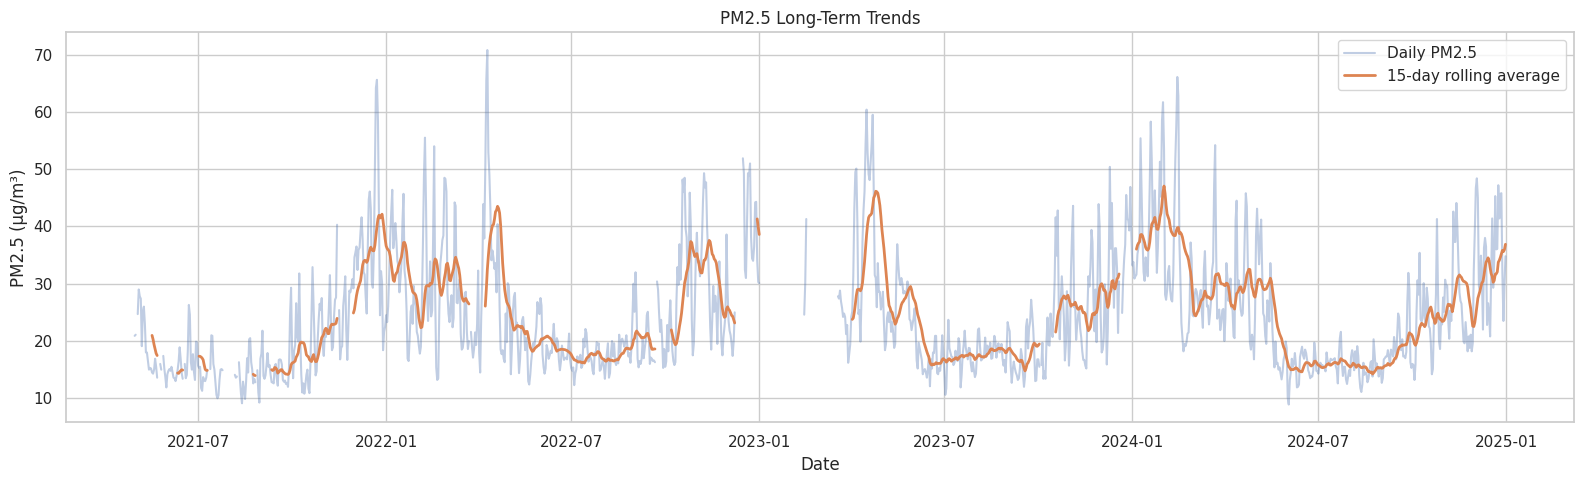

In [ ]:
eda_df["pm25_rolling_15"] = (
    eda_df["pm25"]
    .rolling(window=15, min_periods=15)
    .mean()
)

plt.figure(figsize=(16, 5))

plt.plot(
    eda_df["date"],
    eda_df["pm25"],
    alpha=0.35,
    label="Daily PM2.5"
)

plt.plot(
    eda_df["date"],
    eda_df["pm25_rolling_15"],
    linewidth=2,
    label="15-day rolling average"
)

plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")
plt.title("PM2.5 Long-Term Trends")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "pm25_rolling_average.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

PM2.5 distribution

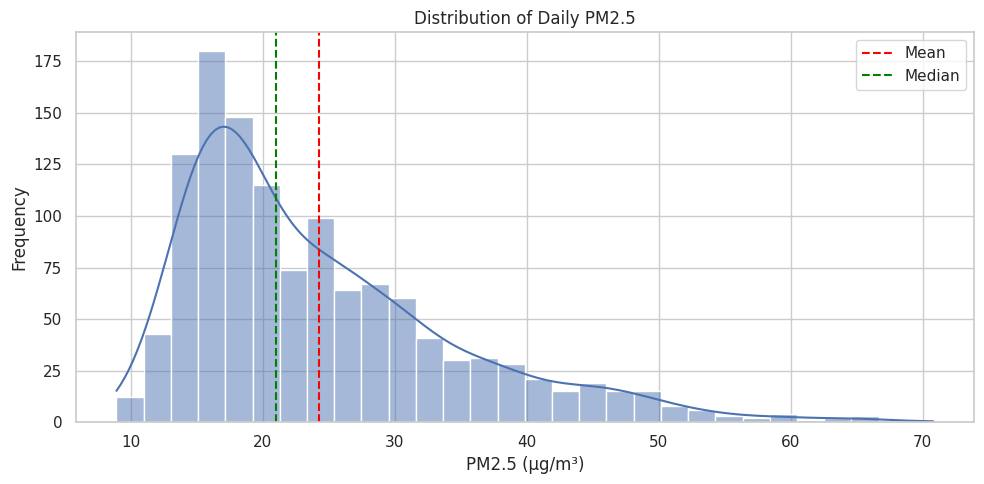

Skewness: 1.2852815569856226


In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    eda_df["pm25"].dropna(),
    bins=30,
    kde=True
)

plt.axvline(
    eda_df["pm25"].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

plt.axvline(
    eda_df["pm25"].median(),
    color="green",
    linestyle="--",
    label="Median"
)

plt.xlabel("PM2.5 (µg/m³)")
plt.ylabel("Frequency")
plt.title("Distribution of Daily PM2.5")
plt.legend()
plt.tight_layout()
plt.show()

print("Skewness:", eda_df["pm25"].skew())

Monthly seasonal analysis

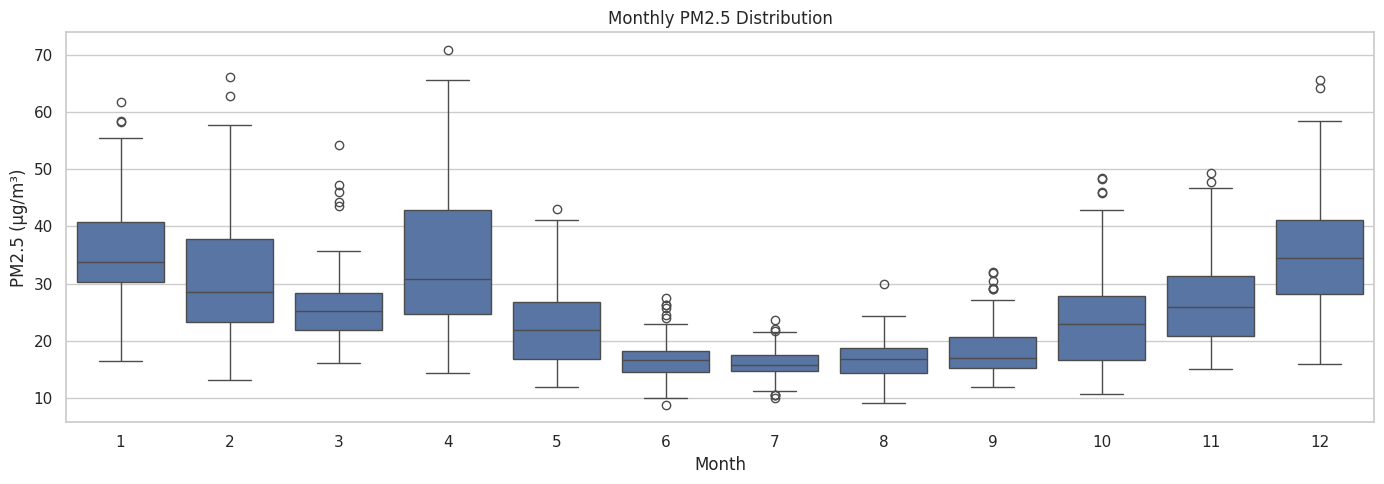

In [ ]:
eda_df["month"] = eda_df["date"].dt.month

plt.figure(figsize=(14, 5))

sns.boxplot(
    data=eda_df,
    x="month",
    y="pm25"
)

plt.xlabel("Month")
plt.ylabel("PM2.5 (µg/m³)")
plt.title("Monthly PM2.5 Distribution")
plt.tight_layout()
plt.show()

In [ ]:
monthly_stats = (
    eda_df.groupby("month")["pm25"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

print(monthly_stats)

       count   mean  median    std    min   max
month                                          
1         63  35.62   33.80   9.86  16.50  61.7
2         60  32.13   28.60  12.56  13.20  66.1
3         74  26.38   25.30   7.07  16.20  54.2
4         91  33.45   30.80  12.40  14.50  70.8
5        120  22.50   21.95   6.70  11.90  43.1
6        119  16.81   16.70   3.23   8.91  27.5
7        116  16.11   15.85   2.63  10.00  23.7
8        118  16.59   16.80   3.18   9.13  30.0
9        119  18.24   17.00   4.65  12.00  32.0
10       123  23.73   22.90   8.49  10.80  48.5
11       119  27.41   26.00   7.98  15.20  49.3
12       115  34.69   34.50  10.00  15.90  65.6


Weather correlation analysis

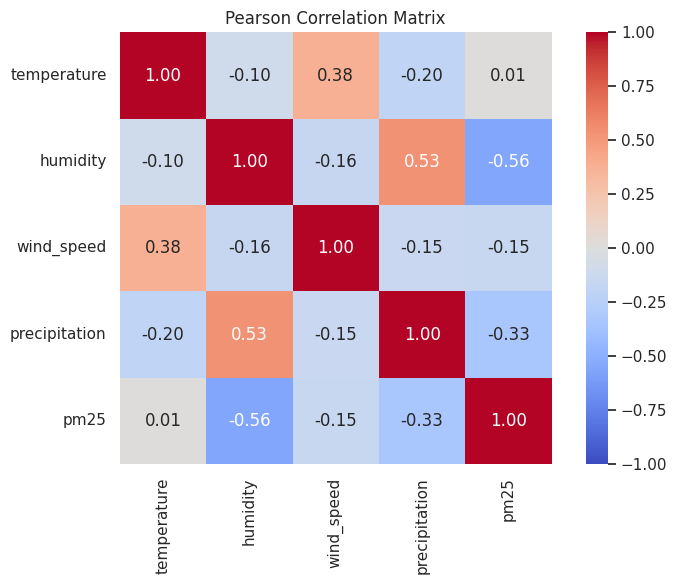

humidity        -0.561438
precipitation   -0.328966
wind_speed      -0.150912
temperature      0.009666
pm25             1.000000
Name: pm25, dtype: float64


In [ ]:
features = [
    "temperature",
    "humidity",
    "wind_speed",
    "precipitation",
    "pm25"
]

correlation = eda_df[features].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Pearson Correlation Matrix")
plt.tight_layout()
plt.show()

print(correlation["pm25"].sort_values())

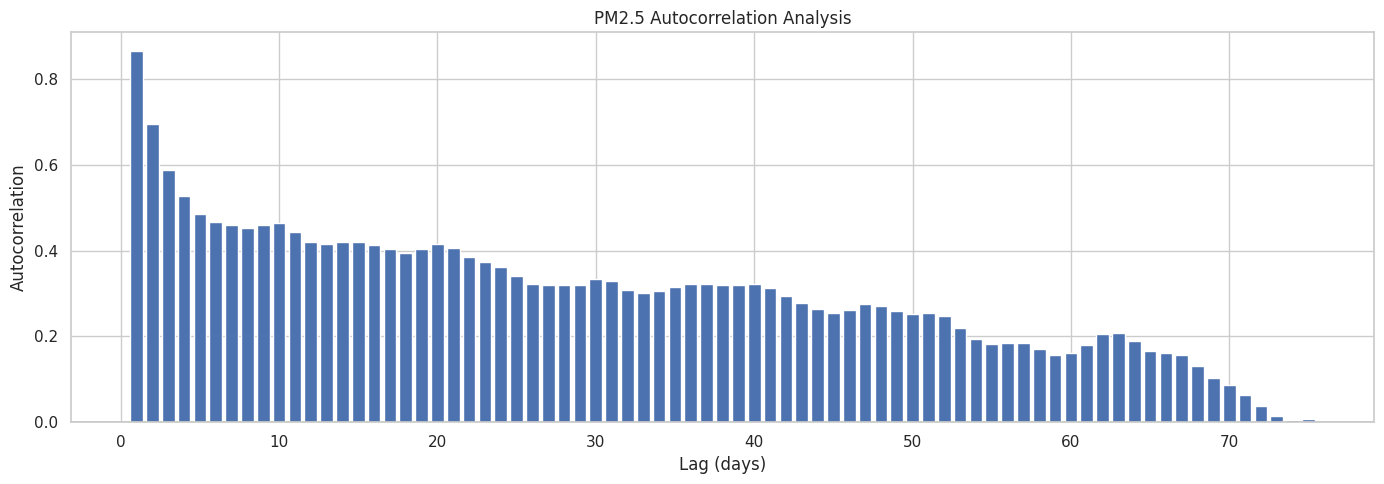

In [ ]:
max_lag = 75

acf_results = []

for lag in range(1, max_lag + 1):

    correlation = eda_df["pm25"].corr(
        eda_df["pm25"].shift(lag)
    )

    acf_results.append({
        "lag": lag,
        "correlation": correlation
    })

acf_df = pd.DataFrame(acf_results)

plt.figure(figsize=(14, 5))

plt.bar(
    acf_df["lag"],
    acf_df["correlation"]
)

plt.axhline(0, color="black", linewidth=1)

plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.title("PM2.5 Autocorrelation Analysis")
plt.tight_layout()
plt.show()

In [ ]:
print(
    acf_df[
        acf_df["lag"].isin(
            [1, 2, 3, 5, 7, 14, 21, 30, 60, 75]
        )
    ].round(3)
)

    lag  correlation
0     1        0.865
1     2        0.695
2     3        0.589
4     5        0.484
6     7        0.459
13   14        0.421
20   21        0.406
29   30        0.335
59   60        0.161
74   75        0.007


Weather yesterday and pm2.5 today correlation

In [ ]:
weather_features = [
    "temperature",
    "humidity",
    "wind_speed",
    "precipitation"
]

tomorrow_pm25 = eda_df["pm25"].shift(-1)

for feature in weather_features:

    r = eda_df[feature].corr(tomorrow_pm25)

    print(f"{feature:15}: {r:.3f}")

temperature    : -0.051
humidity       : -0.588
wind_speed     : -0.173
precipitation  : -0.338


# Feature engineering

In [ ]:
if 'PROJECT_DIR' not in globals():
    from google.colab import drive
    drive.mount('/content/drive')

    from pathlib import Path

    PROJECT_DIR = Path(
        "/content/drive/MyDrive/PM25_Prediction"
    )

    print("Project folder ready:", PROJECT_DIR)
else:
    print("Project folder already established at:", PROJECT_DIR)

Project folder already established at: /content/drive/MyDrive/PM25_Prediction


In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    PROJECT_DIR / "data/processed/pm25_weather_merged.csv",
    parse_dates=["date"]
)

df = df.sort_values("date").reset_index(drop=True)

Choosing what window would be suitable

In [ ]:
window_results = []

for window in [1, 3, 7, 14, 30]:

    # Check whether every historical input
    # and the target are available
    valid = (
        df["pm25"]
        .notna()
        .rolling(window=window + 1)
        .sum()
        .eq(window + 1)
    )

    train = (
        valid &
        (df["date"] < "2025-01-01")
    )

    val = (
        valid &
        (df["date"] >= "2025-01-01") &
        (df["date"] < "2026-01-01")
    )

    test = (
        valid &
        (df["date"] >= "2026-01-01")
    )

    window_results.append({
        "window_size": window,
        "train_samples": train.sum(),
        "val_samples": val.sum(),
        "test_samples": test.sum(),
        "total_samples": valid.sum()
    })

window_results = pd.DataFrame(window_results)

print(window_results)

   window_size  train_samples  val_samples  test_samples  total_samples
0            1           1219          254           276           1749
1            3           1187          244           274           1705
2            7           1135          224           270           1629
3           14           1045          189           263           1497
4           30            906          141           244           1291


In [ ]:
FEATURES = [
    "pm25",
    "temperature",
    "humidity",
    "wind_speed",
    "precipitation"
]

TARGET = "pm25"

WINDOW_SIZE = 7

In [ ]:
def create_sequences(df, features, target, window_size):

    X = []
    y = []
    dates = []

    for i in range(window_size, len(df)):

        # Historical input
        input_window = df.iloc[i-window_size:i][features]

        # Prediction target
        target_value = df.iloc[i][target]

        # Skip missing historical inputs
        if input_window.isna().any().any():
            continue

        # Skip missing prediction target
        if pd.isna(target_value):
            continue

        X.append(input_window.to_numpy())
        y.append(target_value)
        dates.append(df.iloc[i]["date"])

    return (
        np.array(X),
        np.array(y),
        pd.DatetimeIndex(dates)
    )

In [ ]:
X, y, target_dates = create_sequences(
    df,
    FEATURES,
    TARGET,
    WINDOW_SIZE
)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Target dates shape:", target_dates.shape)

X shape: (1629, 7, 5)
y shape: (1629,)
Target dates shape: (1629,)


In [ ]:
print("First input sample:")

print(
    pd.DataFrame(
        X[0],
        columns=FEATURES
    )
)

print("\nTarget PM2.5:", y[0])
print("Target date:", target_dates[0])

First input sample:
   pm25  temperature  humidity  wind_speed  precipitation
0  24.7         29.0      81.0         3.3            1.6
1  29.0         29.5      81.0         4.7           13.9
2  27.8         29.8      79.0         4.6            0.0
3  27.4         27.1      87.0         7.1           10.8
4  19.1         27.5      84.0         7.4            2.8
5  25.2         28.1      85.0         4.5            0.8
6  26.0         28.5      82.0         5.2            1.2

Target PM2.5: 23.0
Target date: 2021-05-10 00:00:00


In [ ]:
train_mask = target_dates < "2025-01-01"

val_mask = (
    (target_dates >= "2025-01-01") &
    (target_dates < "2026-01-01")
)

test_mask = target_dates >= "2026-01-01"

X_train = X[train_mask]
y_train = y[train_mask]

X_val = X[val_mask]
y_val = y[val_mask]

X_test = X[test_mask]
y_test = y[test_mask]

dates_train = target_dates[train_mask]
dates_val = target_dates[val_mask]
dates_test = target_dates[test_mask]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (1135, 7, 5) (1135,)
Validation: (224, 7, 5) (224,)
Testing: (270, 7, 5) (270,)


In [ ]:
X_train_flat = X_train.reshape(len(X_train), -1)
X_val_flat = X_val.reshape(len(X_val), -1)
X_test_flat = X_test.reshape(len(X_test), -1)

In [ ]:
output = (
    PROJECT_DIR
    / "data/processed/dataset_window7.npz"
)

np.savez_compressed(
    output,

    X_train=X_train,
    y_train=y_train,

    X_val=X_val,
    y_val=y_val,

    X_test=X_test,
    y_test=y_test,

    dates_train=dates_train.to_numpy(),
    dates_val=dates_val.to_numpy(),
    dates_test=dates_test.to_numpy(),

    features=np.array(FEATURES),
    window_size=WINDOW_SIZE
)

print("Dataset saved:", output)

Dataset saved: /content/drive/MyDrive/PM25_Prediction/data/processed/dataset_window7.npz


In [ ]:
with np.load(output) as dataset:

    print("Stored arrays:", dataset.files)

    print("Training:", dataset["X_train"].shape)
    print("Validation:", dataset["X_val"].shape)
    print("Testing:", dataset["X_test"].shape)

    assert np.array_equal(
        dataset["X_train"], X_train
    )

    assert np.array_equal(
        dataset["y_train"], y_train
    )

Stored arrays: ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test', 'dates_train', 'dates_val', 'dates_test', 'features', 'window_size']
Training: (1135, 7, 5)
Validation: (224, 7, 5)
Testing: (270, 7, 5)


# Persistence baseline

Base line:
predicting tomorrow's concentration using today's concentration

In [ ]:
if 'PROJECT_DIR' not in globals():
    from google.colab import drive
    drive.mount('/content/drive')

    from pathlib import Path

    PROJECT_DIR = Path(
        "/content/drive/MyDrive/PM25_Prediction"
    )

    print("Project folder ready:", PROJECT_DIR)
else:
    print("Project folder already established at:", PROJECT_DIR)

In [ ]:
dataset = np.load(
    PROJECT_DIR / "data/processed/dataset_window7.npz"
)

X_train = dataset["X_train"]
y_train = dataset["y_train"]

X_val = dataset["X_val"]
y_val = dataset["y_val"]

dates_val = dataset["dates_val"]

FEATURES = dataset["features"].tolist()

print("Features:", FEATURES)

Features: ['pm25', 'temperature', 'humidity', 'wind_speed', 'precipitation']


In [ ]:
pm25_index = FEATURES.index("pm25")

y_train_pred = X_train[:, -1, pm25_index]
y_val_pred = X_val[:, -1, pm25_index]

print("First 5 predictions:", y_val_pred[:5])
print("First 5 actual values:", y_val[:5])

First 5 predictions: [34.8 35.1 39.4 43.  35.7]
First 5 actual values: [35.1 39.4 43.  35.7 41. ]


In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

def evaluate_model(y_true, y_pred):

    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    r2 = r2_score(y_true, y_pred)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

In [ ]:
train_results = evaluate_model(
    y_train, y_train_pred
)

val_results = evaluate_model(
    y_val, y_val_pred
)

results = pd.DataFrame(
    [train_results, val_results],
    index=["Training", "Validation"]
)

print(results.round(4))

               MAE    RMSE      R2
Training    3.7920  5.4096  0.7263
Validation  4.3737  6.2417  0.8117


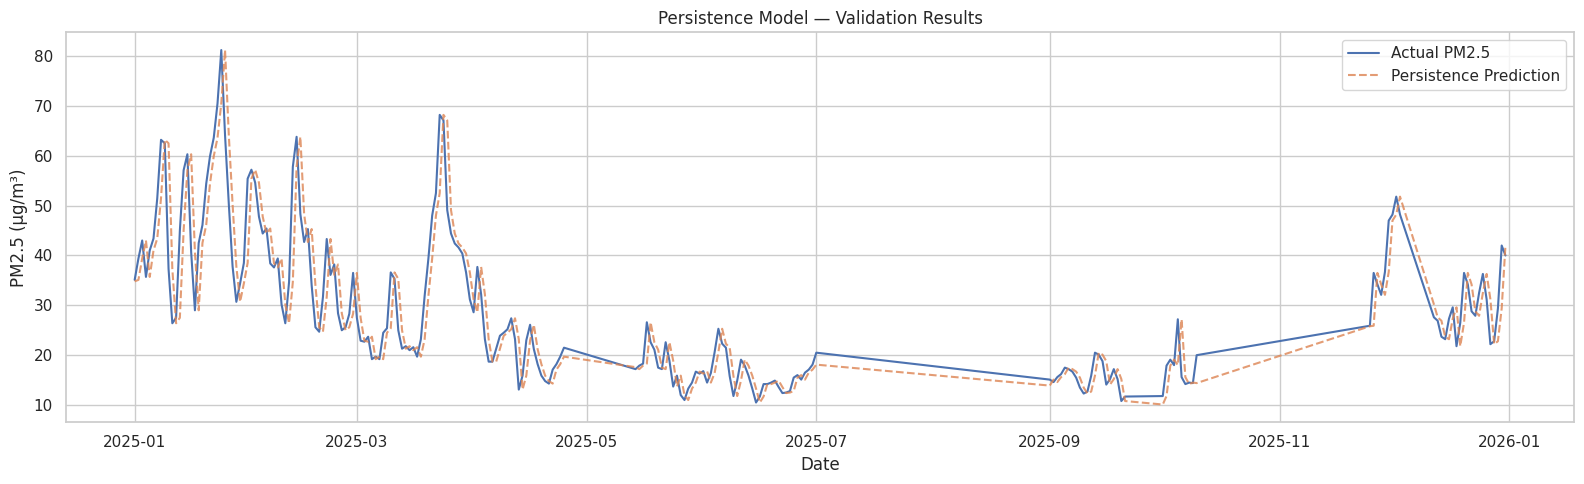

In [ ]:
plt.figure(figsize=(16, 5))

plt.plot(
    dates_val,
    y_val,
    label="Actual PM2.5",
    linewidth=1.5
)

plt.plot(
    dates_val,
    y_val_pred,
    label="Persistence Prediction",
    linestyle="--",
    alpha=0.8
)

plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")
plt.title("Persistence Model — Validation Results")
plt.legend()
plt.tight_layout()
plt.show()

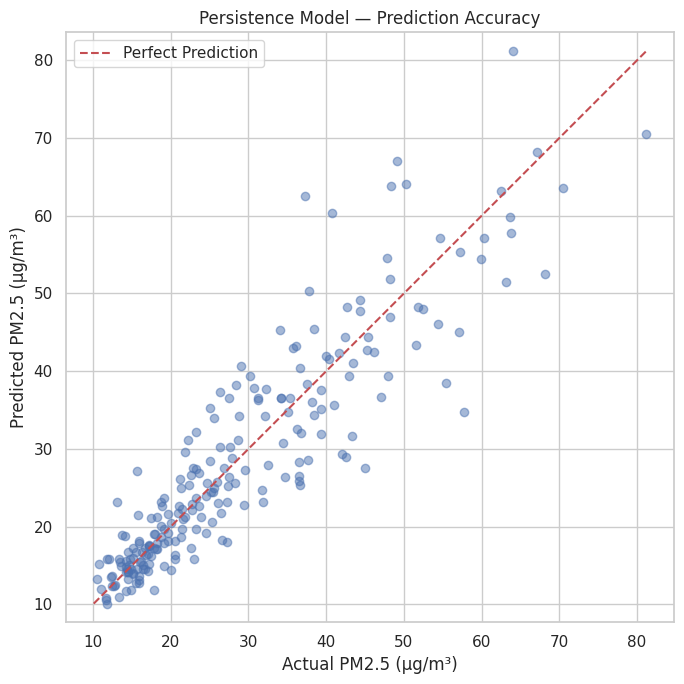

In [ ]:
plt.figure(figsize=(7, 7))

plt.scatter(
    y_val,
    y_val_pred,
    alpha=0.5
)

lower = min(y_val.min(), y_val_pred.min())
upper = max(y_val.max(), y_val_pred.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual PM2.5 (µg/m³)")
plt.ylabel("Predicted PM2.5 (µg/m³)")
plt.title("Persistence Model — Prediction Accuracy")
plt.legend()
plt.axis("equal")
plt.tight_layout()
plt.show()

# Random forest

In [ ]:
if 'PROJECT_DIR' not in globals():
    from google.colab import drive
    drive.mount('/content/drive')

    from pathlib import Path

    PROJECT_DIR = Path(
        "/content/drive/MyDrive/PM25_Prediction"
    )

    print("Project folder ready:", PROJECT_DIR)
else:
    print("Project folder already established at:", PROJECT_DIR)

Project folder already established at: /content/drive/MyDrive/PM25_Prediction


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

dataset = np.load(
    PROJECT_DIR / "data/processed/dataset_window7.npz"
)

X_train = dataset["X_train"]
y_train = dataset["y_train"]

X_val = dataset["X_val"]
y_val = dataset["y_val"]

dates_val = dataset["dates_val"]

FEATURES = dataset["features"].tolist()
WINDOW_SIZE = int(dataset["window_size"])

print("Training:", X_train.shape)
print("Validation:", X_val.shape)

Training: (1135, 7, 5)
Validation: (224, 7, 5)


In [ ]:
X_train_flat = X_train.reshape(len(X_train), -1)
X_val_flat = X_val.reshape(len(X_val), -1)

print("Training:", X_train_flat.shape)
print("Validation:", X_val_flat.shape)

Training: (1135, 35)
Validation: (224, 35)


In [ ]:
from sklearn.ensemble import RandomForestRegressor
import time

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

start_time = time.perf_counter()

rf_model.fit(X_train_flat, y_train)

training_time = time.perf_counter() - start_time

print(f"Training time: {training_time:.3f} seconds")

Training time: 3.463 seconds


In [ ]:
y_train_pred = rf_model.predict(X_train_flat)
y_val_pred = rf_model.predict(X_val_flat)

In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

def evaluate_model(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "R2": r2_score(y_true, y_pred)
    }

results = pd.DataFrame(
    [
        evaluate_model(y_train, y_train_pred),
        evaluate_model(y_val, y_val_pred)
    ],
    index=["Training", "Validation"]
)

print(results.round(4))

               MAE    RMSE      R2
Training    1.2936  1.8149  0.9692
Validation  4.5794  6.6754  0.7846


In [ ]:
pm25_index = FEATURES.index("pm25")

persistence_pred = X_val[:, -1, pm25_index]

comparison = pd.DataFrame({
    "Persistence": evaluate_model(
        y_val, persistence_pred
    ),
    "Random Forest": evaluate_model(
        y_val, y_val_pred
    )
}).T

print(comparison.round(4))

                  MAE    RMSE      R2
Persistence    4.3737  6.2417  0.8117
Random Forest  4.5794  6.6754  0.7846


In [ ]:
for metric in ["MAE", "RMSE"]:

    baseline = comparison.loc["Persistence", metric]
    rf = comparison.loc["Random Forest", metric]

    improvement = (baseline - rf) / baseline * 100

    print(f"{metric} improvement: {improvement:.2f}%")

MAE improvement: -4.70%
RMSE improvement: -6.95%


In [ ]:
feature_names = [
    f"{feature}_lag{lag}"
    for lag in range(WINDOW_SIZE, 0, -1)
    for feature in FEATURES
]

importance = pd.DataFrame({
    "feature": feature_names,
    "importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    "importance",
    ascending=False
)

print(importance.head(15))

               feature  importance
30           pm25_lag1    0.762973
28     wind_speed_lag2    0.018114
34  precipitation_lag1    0.016473
33     wind_speed_lag1    0.013375
25           pm25_lag2    0.012961
32       humidity_lag1    0.012952
23     wind_speed_lag3    0.011652
31    temperature_lag1    0.009406
13     wind_speed_lag5    0.008320
26    temperature_lag2    0.008279
0            pm25_lag7    0.008214
8      wind_speed_lag6    0.007100
10           pm25_lag5    0.006937
29  precipitation_lag2    0.006928
27       humidity_lag2    0.006791


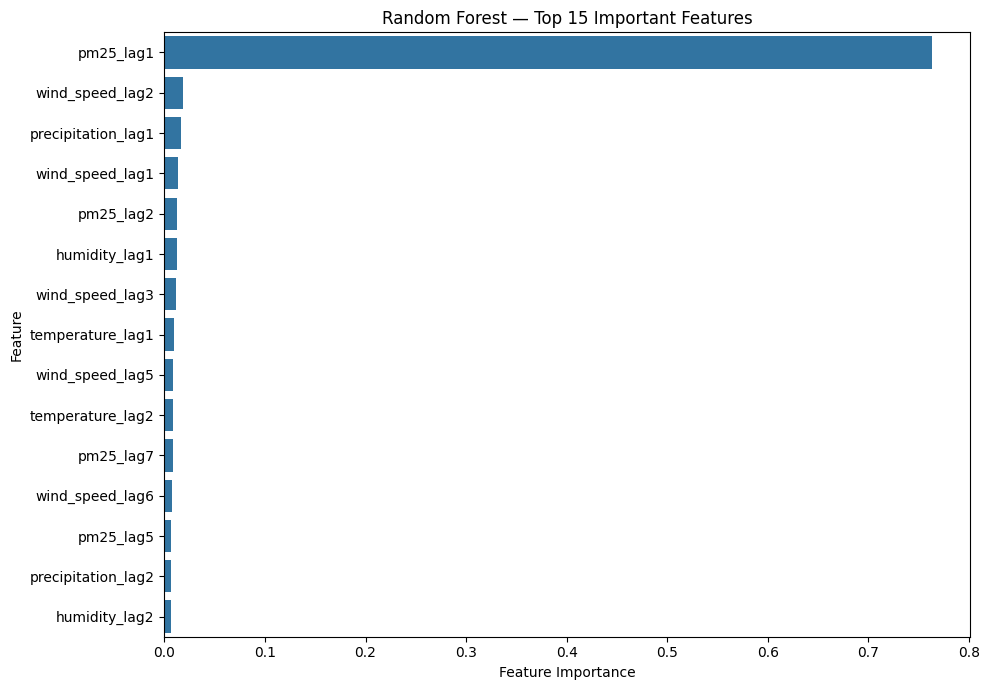

In [ ]:
import seaborn as sns

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance.head(15),
    x="importance",
    y="feature"
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest — Top 15 Important Features")
plt.tight_layout()
plt.show()

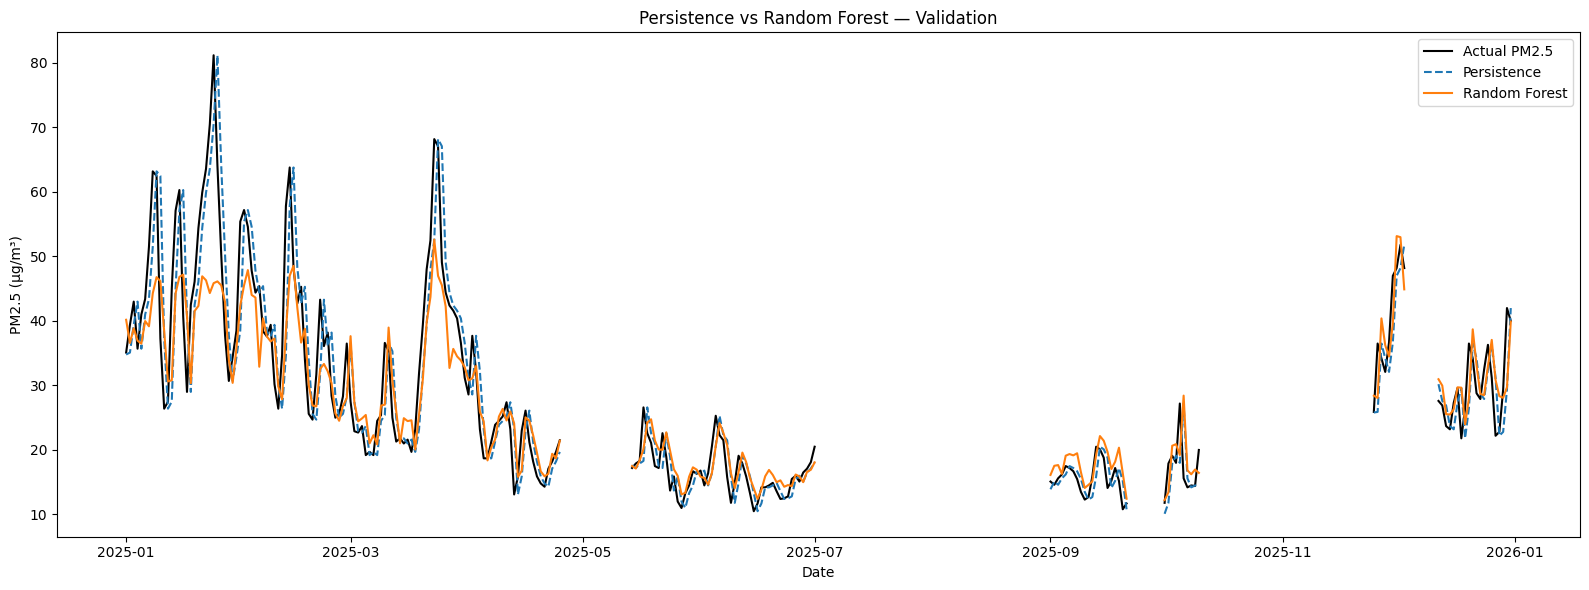

In [ ]:
plot_df = pd.DataFrame({
    "Actual": y_val,
    "Persistence": persistence_pred,
    "Random Forest": y_val_pred
}, index=pd.to_datetime(dates_val))

full_dates = pd.date_range(
    "2025-01-01",
    "2025-12-31",
    freq="D"
)

plot_df = plot_df.reindex(full_dates)

plt.figure(figsize=(16, 6))

plt.plot(
    plot_df.index,
    plot_df["Actual"],
    color="black",
    label="Actual PM2.5"
)

plt.plot(
    plot_df.index,
    plot_df["Persistence"],
    linestyle="--",
    label="Persistence"
)

plt.plot(
    plot_df.index,
    plot_df["Random Forest"],
    label="Random Forest"
)

plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")
plt.title("Persistence vs Random Forest — Validation")
plt.legend()
plt.tight_layout()
plt.show()

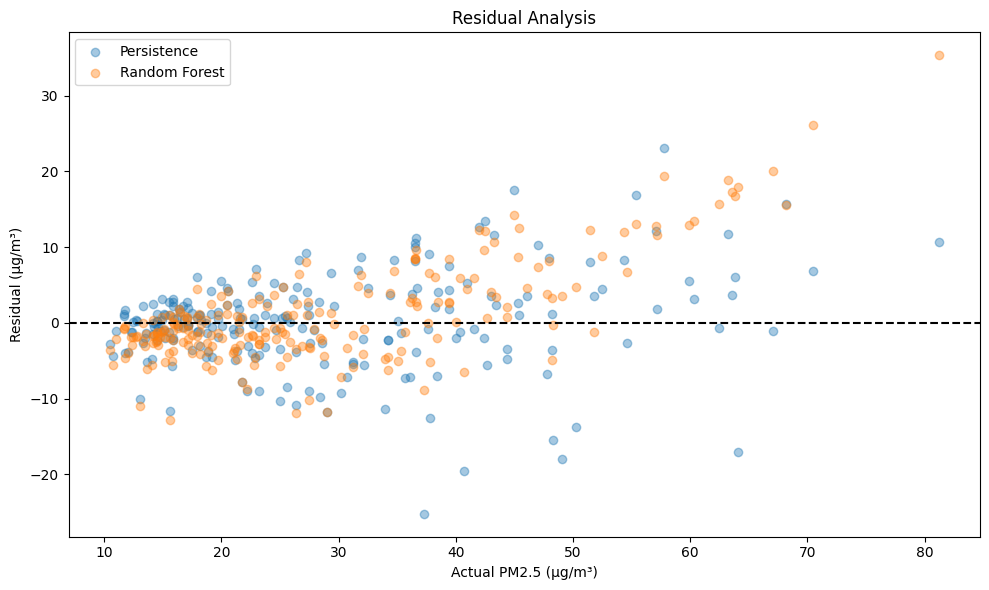

In [ ]:
persistence_residuals = y_val - persistence_pred
rf_residuals = y_val - y_val_pred

plt.figure(figsize=(10, 6))

plt.scatter(
    y_val,
    persistence_residuals,
    alpha=0.4,
    label="Persistence"
)

plt.scatter(
    y_val,
    rf_residuals,
    alpha=0.4,
    label="Random Forest"
)

plt.axhline(
    0,
    color="black",
    linestyle="--"
)

plt.xlabel("Actual PM2.5 (µg/m³)")
plt.ylabel("Residual (µg/m³)")
plt.title("Residual Analysis")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
grouped_importance = importance.copy()

grouped_importance["variable"] = (
    grouped_importance["feature"]
    .str.replace(r"_lag\d+$", "", regex=True)
)

grouped_importance = (
    grouped_importance
    .groupby("variable")["importance"]
    .sum()
    .sort_values(ascending=False)
)

print(grouped_importance)

variable
pm25             0.808451
wind_speed       0.068585
precipitation    0.045618
humidity         0.039340
temperature      0.038005
Name: importance, dtype: float64


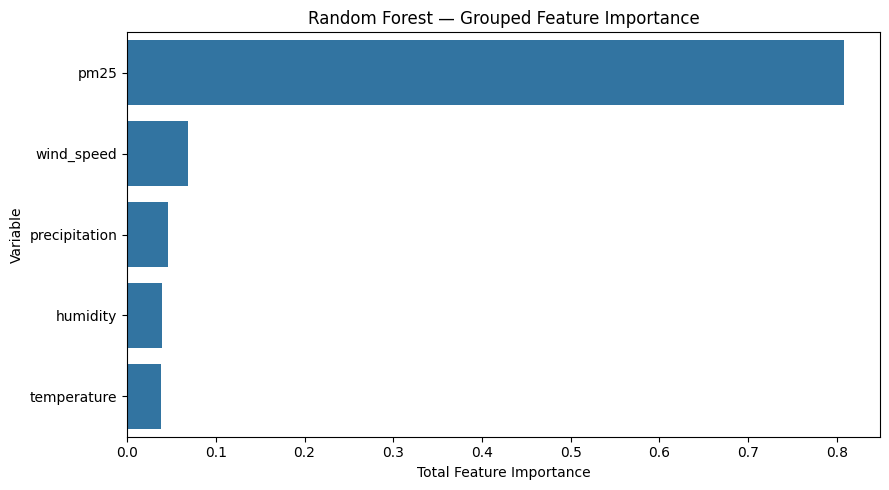

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=grouped_importance.values,
    y=grouped_importance.index
)

plt.xlabel("Total Feature Importance")
plt.ylabel("Variable")
plt.title("Random Forest — Grouped Feature Importance")
plt.tight_layout()
plt.show()

In [ ]:
print("Training maximum:", y_train.max())
print("Validation maximum:", y_val.max())
print("Random Forest maximum:", y_val_pred.max())
print("Persistence maximum:", persistence_pred.max())

Training maximum: 70.8
Validation maximum: 81.2
Random Forest maximum: 53.159
Persistence maximum: 81.2


In [ ]:
error_analysis = pd.DataFrame({
    "actual": y_val,
    "persistence": persistence_pred,
    "random_forest": y_val_pred
})

error_analysis["pollution_level"] = pd.cut(
    error_analysis["actual"],
    bins=[0, 20, 35, 50, np.inf],
    labels=["0-20", "20-35", "35-50", "50+"],
    include_lowest=True
)

for model in ["persistence", "random_forest"]:

    error_analysis[f"{model}_residual"] = (
        error_analysis["actual"]
        - error_analysis[model]
    )

    error_analysis[f"{model}_abs_error"] = (
        error_analysis[f"{model}_residual"].abs()
    )

summary = (
    error_analysis
    .groupby("pollution_level", observed=True)
    .agg(
        samples=("actual", "size"),
        persistence_MAE=("persistence_abs_error", "mean"),
        rf_MAE=("random_forest_abs_error", "mean"),
        persistence_bias=("persistence_residual", "mean"),
        rf_bias=("random_forest_residual", "mean")
    )
)

print(summary.round(3))

                 samples  persistence_MAE  rf_MAE  persistence_bias  rf_bias
pollution_level                                                             
0-20                  83            2.027   2.407            -0.460   -1.865
20-35                 74            4.253   3.535            -0.836   -1.267
35-50                 46            6.950   5.463             0.502    3.822
50+                   21            8.433  14.911             5.071   14.797


In [ ]:
depth_results = []

for depth in [3, 5, 7, 10, 15, None]:

    model = RandomForestRegressor(
        n_estimators=100,
        max_depth=depth,
        random_state=42,
        n_jobs=-1
    )

    start_time = time.perf_counter()

    model.fit(X_train_flat, y_train)

    elapsed = time.perf_counter() - start_time

    train_pred = model.predict(X_train_flat)
    val_pred = model.predict(X_val_flat)

    train_metrics = evaluate_model(y_train, train_pred)
    val_metrics = evaluate_model(y_val, val_pred)

    depth_results.append({
        "max_depth": str(depth),
        "train_MAE": train_metrics["MAE"],
        "train_RMSE": train_metrics["RMSE"],
        "val_MAE": val_metrics["MAE"],
        "val_RMSE": val_metrics["RMSE"],
        "val_R2": val_metrics["R2"],
        "training_time": elapsed
    })

depth_results = pd.DataFrame(depth_results)

print(depth_results.round(4))

  max_depth  train_MAE  train_RMSE  val_MAE  val_RMSE  val_R2  training_time
0         3     3.4944      4.7815   4.6929    7.0005  0.7631         0.4728
1         5     2.8456      3.8189   4.5549    6.7256  0.7814         0.7666
2         7     2.2286      2.9186   4.5386    6.6097  0.7888         1.0781
3        10     1.6110      2.1181   4.5126    6.5569  0.7922         1.5170
4        15     1.3208      1.8317   4.5157    6.5262  0.7941         1.9542
5      None     1.2936      1.8149   4.5794    6.6754  0.7846         2.0194


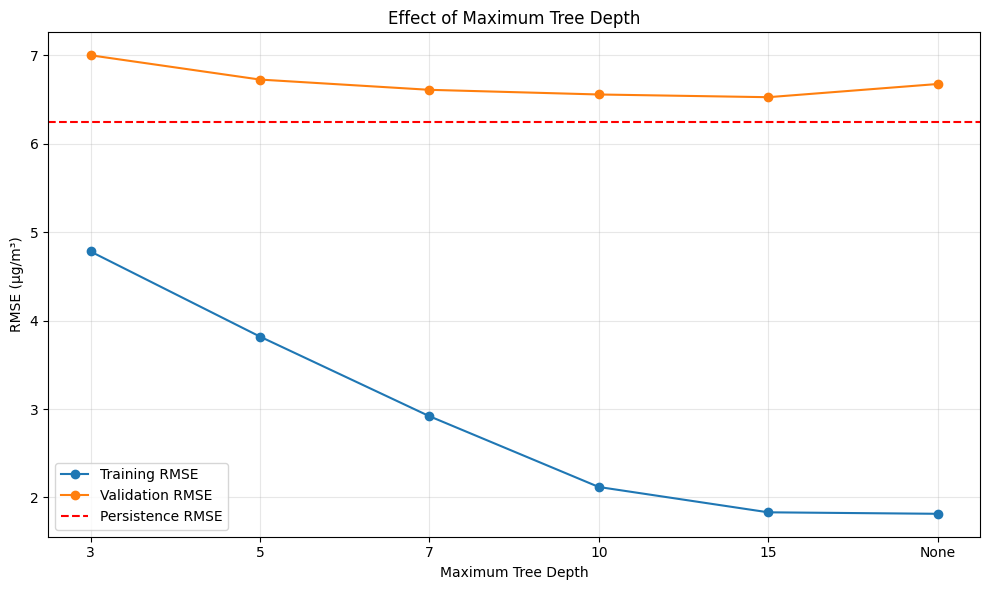

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    depth_results["max_depth"],
    depth_results["train_RMSE"],
    marker="o",
    label="Training RMSE"
)

plt.plot(
    depth_results["max_depth"],
    depth_results["val_RMSE"],
    marker="o",
    label="Validation RMSE"
)

plt.axhline(
    6.2417,
    color="red",
    linestyle="--",
    label="Persistence RMSE"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("RMSE (µg/m³)")
plt.title("Effect of Maximum Tree Depth")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
leaf_results = []

for leaf in [1, 2, 4, 8, 16, 32]:

    model = RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=leaf,
        random_state=42,
        n_jobs=-1
    )

    start_time = time.perf_counter()

    model.fit(X_train_flat, y_train)

    elapsed = time.perf_counter() - start_time

    train_pred = model.predict(X_train_flat)
    val_pred = model.predict(X_val_flat)

    train_metrics = evaluate_model(
        y_train, train_pred
    )

    val_metrics = evaluate_model(
        y_val, val_pred
    )

    leaf_results.append({
        "min_samples_leaf": leaf,
        "train_MAE": train_metrics["MAE"],
        "train_RMSE": train_metrics["RMSE"],
        "val_MAE": val_metrics["MAE"],
        "val_RMSE": val_metrics["RMSE"],
        "val_R2": val_metrics["R2"],
        "training_time": elapsed
    })

leaf_results = pd.DataFrame(leaf_results)

print(leaf_results.round(4))

   min_samples_leaf  train_MAE  train_RMSE  val_MAE  val_RMSE  val_R2  \
0                 1     1.3208      1.8317   4.5157    6.5262  0.7941   
1                 2     1.4369      2.0644   4.4914    6.5542  0.7924   
2                 4     1.8180      2.6504   4.5677    6.7460  0.7800   
3                 8     2.3966      3.4153   4.5541    6.7660  0.7787   
4                16     2.9128      4.1384   4.5541    6.6840  0.7841   
5                32     3.3087      4.6867   4.5734    6.6230  0.7880   

   training_time  
0         2.4400  
1         2.7864  
2         1.5790  
3         1.0037  
4         0.7777  
5         0.6082  


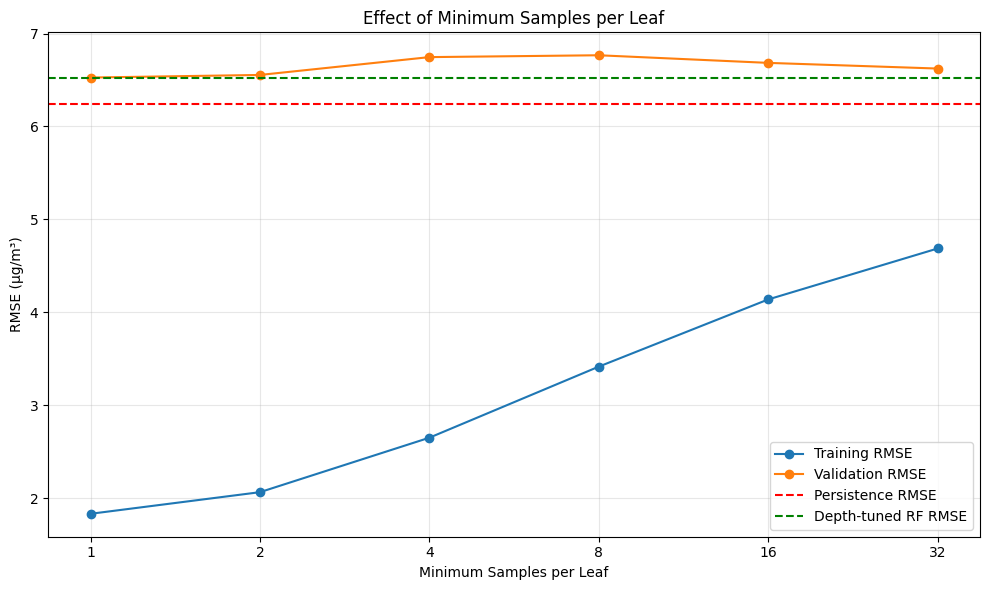

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    leaf_results["min_samples_leaf"],
    leaf_results["train_RMSE"],
    marker="o",
    label="Training RMSE"
)

plt.plot(
    leaf_results["min_samples_leaf"],
    leaf_results["val_RMSE"],
    marker="o",
    label="Validation RMSE"
)

plt.axhline(
    6.2417,
    color="red",
    linestyle="--",
    label="Persistence RMSE"
)

plt.axhline(
    6.5262,
    color="green",
    linestyle="--",
    label="Depth-tuned RF RMSE"
)

plt.xscale("log", base=2)

plt.xticks(
    [1, 2, 4, 8, 16, 32],
    [1, 2, 4, 8, 16, 32]
)

plt.xlabel("Minimum Samples per Leaf")
plt.ylabel("RMSE (µg/m³)")
plt.title("Effect of Minimum Samples per Leaf")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
estimator_results = []

for n in [10, 25, 50, 100, 200, 300, 500, 1000]:

    model = RandomForestRegressor(
        n_estimators=n,
        max_depth=15,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    )

    start_time = time.perf_counter()

    model.fit(X_train_flat, y_train)

    elapsed = time.perf_counter() - start_time

    train_pred = model.predict(X_train_flat)
    val_pred = model.predict(X_val_flat)

    train_metrics = evaluate_model(
        y_train, train_pred
    )

    val_metrics = evaluate_model(
        y_val, val_pred
    )

    estimator_results.append({
        "n_estimators": n,
        "train_MAE": train_metrics["MAE"],
        "train_RMSE": train_metrics["RMSE"],
        "val_MAE": val_metrics["MAE"],
        "val_RMSE": val_metrics["RMSE"],
        "val_R2": val_metrics["R2"],
        "training_time": elapsed
    })

estimator_results = pd.DataFrame(estimator_results)

print(estimator_results.round(4))

   n_estimators  train_MAE  train_RMSE  val_MAE  val_RMSE  val_R2  \
0            10     1.4841      2.2130   4.6608    6.7274  0.7812   
1            25     1.3650      1.9504   4.6478    6.6541  0.7860   
2            50     1.3297      1.8654   4.5576    6.5990  0.7895   
3           100     1.3208      1.8317   4.5157    6.5262  0.7941   
4           200     1.3035      1.7993   4.5311    6.5837  0.7905   
5           300     1.3041      1.7974   4.5425    6.6142  0.7885   
6           500     1.3041      1.7967   4.5784    6.6886  0.7838   
7          1000     1.2982      1.7914   4.5599    6.6634  0.7854   

   training_time  
0         0.2027  
1         0.5190  
2         0.9667  
3         1.9118  
4         4.7377  
5         6.6927  
6        11.5508  
7        21.1143  


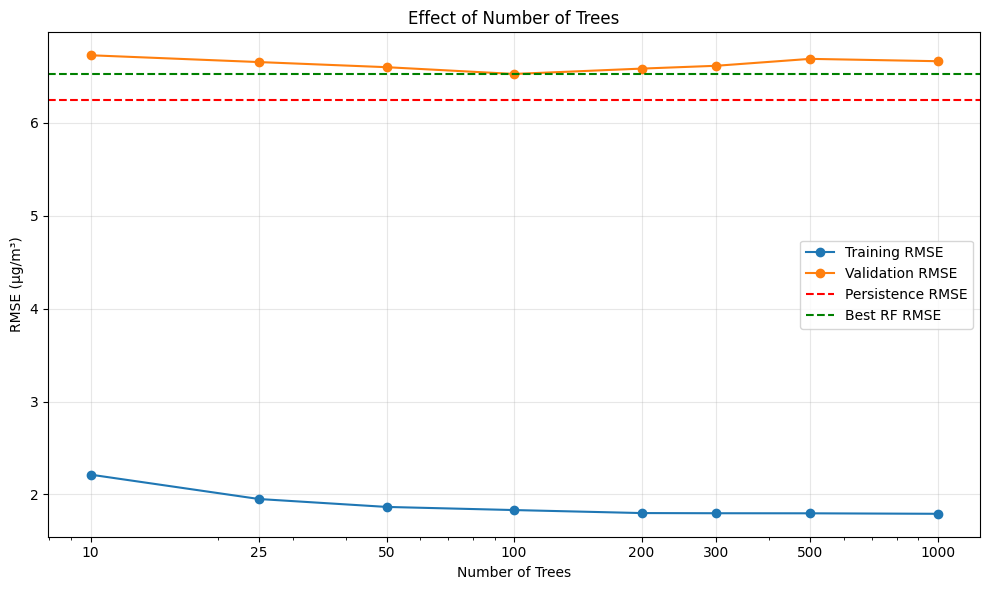

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    estimator_results["n_estimators"],
    estimator_results["train_RMSE"],
    marker="o",
    label="Training RMSE"
)

plt.plot(
    estimator_results["n_estimators"],
    estimator_results["val_RMSE"],
    marker="o",
    label="Validation RMSE"
)

plt.axhline(
    6.2417,
    color="red",
    linestyle="--",
    label="Persistence RMSE"
)

plt.axhline(
    6.5262,
    color="green",
    linestyle="--",
    label="Best RF RMSE"
)

plt.xscale("log")

plt.xticks(
    estimator_results["n_estimators"],
    estimator_results["n_estimators"]
)

plt.xlabel("Number of Trees")
plt.ylabel("RMSE (µg/m³)")
plt.title("Effect of Number of Trees")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
max_features_results = []

for max_f in ["sqrt", 0.3, 0.5, 0.7, 1.0]:

    model = RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=1,
        max_features=max_f,
        random_state=42,
        n_jobs=-1
    )

    start_time = time.perf_counter()

    model.fit(X_train_flat, y_train)

    elapsed = time.perf_counter() - start_time

    train_pred = model.predict(X_train_flat)
    val_pred = model.predict(X_val_flat)

    train_metrics = evaluate_model(
        y_train, train_pred
    )

    val_metrics = evaluate_model(
        y_val, val_pred
    )

    max_features_results.append({
        "max_features": str(max_f),
        "train_MAE": train_metrics["MAE"],
        "train_RMSE": train_metrics["RMSE"],
        "val_MAE": val_metrics["MAE"],
        "val_RMSE": val_metrics["RMSE"],
        "val_R2": val_metrics["R2"],
        "training_time": elapsed
    })

max_features_results = pd.DataFrame(
    max_features_results
)

print(max_features_results.round(4))

  max_features  train_MAE  train_RMSE  val_MAE  val_RMSE  val_R2  \
0         sqrt     1.4970      2.0307   5.2256    7.2416  0.7465   
1          0.3     1.3900      1.9028   4.6341    6.6002  0.7894   
2          0.5     1.3668      1.8924   4.4867    6.4152  0.8011   
3          0.7     1.3258      1.8382   4.4756    6.4100  0.8014   
4          1.0     1.3208      1.8317   4.5157    6.5262  0.7941   

   training_time  
0         0.4114  
1         0.7187  
2         1.7839  
3         2.5285  
4         1.9718  


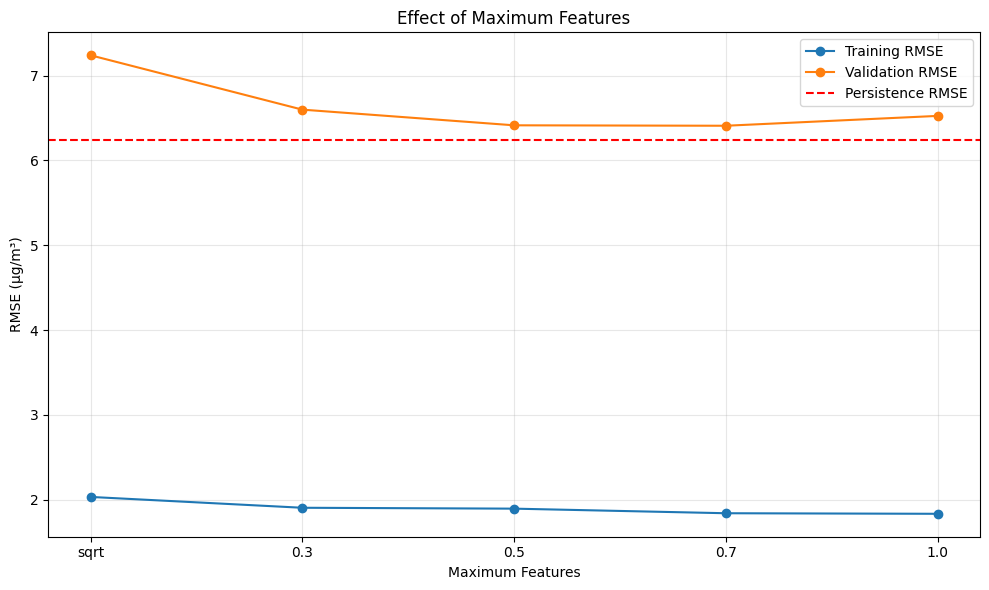

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    max_features_results["max_features"],
    max_features_results["train_RMSE"],
    marker="o",
    label="Training RMSE"
)

plt.plot(
    max_features_results["max_features"],
    max_features_results["val_RMSE"],
    marker="o",
    label="Validation RMSE"
)

plt.axhline(
    6.2417,
    color="red",
    linestyle="--",
    label="Persistence RMSE"
)

plt.xlabel("Maximum Features")
plt.ylabel("RMSE (µg/m³)")
plt.title("Effect of Maximum Features")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
import joblib

rf_tuned = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=1,
    max_features=0.7,
    random_state=42,
    n_jobs=-1
)

rf_tuned.fit(X_train_flat, y_train)

tuned_train_pred = rf_tuned.predict(X_train_flat)
tuned_val_pred = rf_tuned.predict(X_val_flat)

output = PROJECT_DIR / "models/random_forest_tuned.joblib"

output.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(rf_tuned, output)

print("Model saved:", output)

print(evaluate_model(y_val, tuned_val_pred))

Model saved: /content/drive/MyDrive/PM25_Prediction/models/random_forest_tuned.joblib
{'MAE': 4.475593825936897, 'RMSE': np.float64(6.4099760574585245), 'R2': 0.8014028551744836}


# Residual Random forest

In [ ]:
if 'PROJECT_DIR' not in globals():
    from google.colab import drive
    drive.mount('/content/drive')

    from pathlib import Path

    PROJECT_DIR = Path(
        "/content/drive/MyDrive/PM25_Prediction"
    )

    print("Project folder ready:", PROJECT_DIR)
else:
    print("Project folder already established at:", PROJECT_DIR)

Project folder already established at: /content/drive/MyDrive/PM25_Prediction


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

dataset = np.load(
    PROJECT_DIR / "data/processed/dataset_window7.npz"
)

X_train = dataset["X_train"]
y_train = dataset["y_train"]

X_val = dataset["X_val"]
y_val = dataset["y_val"]

dates_val = dataset["dates_val"]

FEATURES = dataset["features"].tolist()
WINDOW_SIZE = int(dataset["window_size"])

print("Training:", X_train.shape)
print("Validation:", X_val.shape)

Training: (1135, 7, 5)
Validation: (224, 7, 5)


In [ ]:
pm25_index = FEATURES.index("pm25")

# Today's PM2.5 for every sample
today_train = X_train[:, -1, pm25_index]
today_val = X_val[:, -1, pm25_index]

# Tomorrow's PM2.5 minus today's PM2.5
y_train_delta = y_train - today_train
y_val_delta = y_val - today_val

print("Original targets:", y_train[:5])
print("Today's PM2.5:", today_train[:5])
print("Residual targets:", y_train_delta[:5])

Original targets: [23.  18.  18.  16.5 15. ]
Today's PM2.5: [26.  23.  18.  18.  16.5]
Residual targets: [-3.  -5.   0.  -1.5 -1.5]


In [ ]:
X_train_flat = X_train.reshape(len(X_train), -1)
X_val_flat = X_val.reshape(len(X_val), -1)

print("Training:", X_train_flat.shape)
print("Validation:", X_val_flat.shape)

Training: (1135, 35)
Validation: (224, 35)


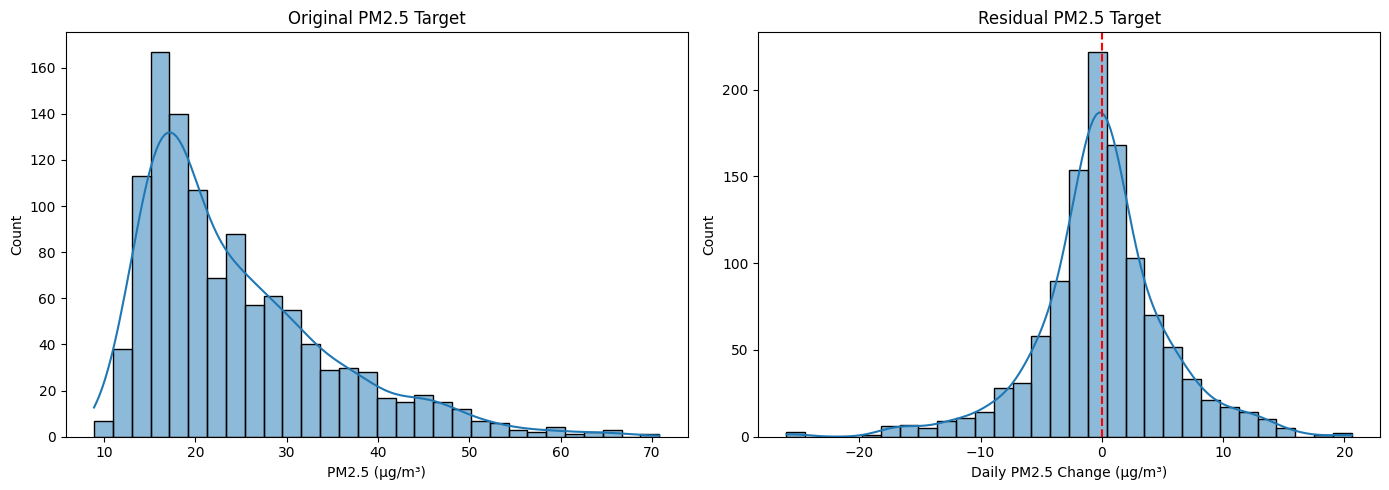

In [ ]:
import seaborn as sns
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    y_train,
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Original PM2.5 Target")
axes[0].set_xlabel("PM2.5 (µg/m³)")

sns.histplot(
    y_train_delta,
    bins=30,
    kde=True,
    ax=axes[1]
)

axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("Residual PM2.5 Target")
axes[1].set_xlabel("Daily PM2.5 Change (µg/m³)")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestRegressor
import time

rf_residual = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=1,
    max_features=0.7,
    random_state=42,
    n_jobs=-1
)

start_time = time.perf_counter()

rf_residual.fit(
    X_train_flat,
    y_train_delta
)

training_time = time.perf_counter() - start_time

print(f"Training time: {training_time:.3f} seconds")

Training time: 1.611 seconds


In [ ]:
import joblib

joblib.dump(
    rf_residual,
    PROJECT_DIR / "models/random_forest_residual.joblib"
)

In [ ]:
# Predict the change in PM2.5
delta_train_pred = rf_residual.predict(X_train_flat)
delta_val_pred = rf_residual.predict(X_val_flat)

# Reconstruct absolute PM2.5 predictions
residual_train_pred = today_train + delta_train_pred
residual_val_pred = today_val + delta_val_pred

In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

def evaluate_model(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "R2": r2_score(y_true, y_pred)
    }

residual_results = pd.DataFrame(
    [
        evaluate_model(y_train, residual_train_pred),
        evaluate_model(y_val, residual_val_pred)
    ],
    index=["Training", "Validation"]
)

print(residual_results.round(4))

               MAE    RMSE      R2
Training    1.4665  1.9239  0.9654
Validation  3.9440  5.5539  0.8509


In [ ]:
import joblib
import numpy as np
import pandas as pd

# Load shared dataset from Google Drive
with np.load(
    PROJECT_DIR / "data/processed/dataset_window7.npz"
) as dataset:

    X_val = dataset["X_val"]
    y_val = dataset["y_val"]
    FEATURES = dataset["features"].tolist()

# Prepare Random Forest inputs
X_val_flat = X_val.reshape(len(X_val), -1)

# Load trained models from Google Drive

rf_tuned = joblib.load(
    PROJECT_DIR / "models/random_forest_tuned.joblib"
)

# Generate persistence predictions
pm25_index = FEATURES.index("pm25")
today_val = X_val[:, -1, pm25_index]

# Generate Random Forest predictions
tuned_val_pred = rf_tuned.predict(X_val_flat)

# Generate residual predictions
delta_val_pred = rf_residual.predict(X_val_flat)
residual_val_pred = today_val + delta_val_pred

# Compare model performance
comparison = pd.DataFrame({
    "Persistence": evaluate_model(
        y_val, today_val
    ),

    "Tuned Random Forest": evaluate_model(
        y_val, tuned_val_pred
    ),

    "Residual Random Forest": evaluate_model(
        y_val, residual_val_pred
    )
}).T

print(comparison.round(4))

                           MAE    RMSE      R2
Persistence             4.3737  6.2417  0.8117
Tuned Random Forest     4.4756  6.4100  0.8014
Residual Random Forest  3.9440  5.5539  0.8509


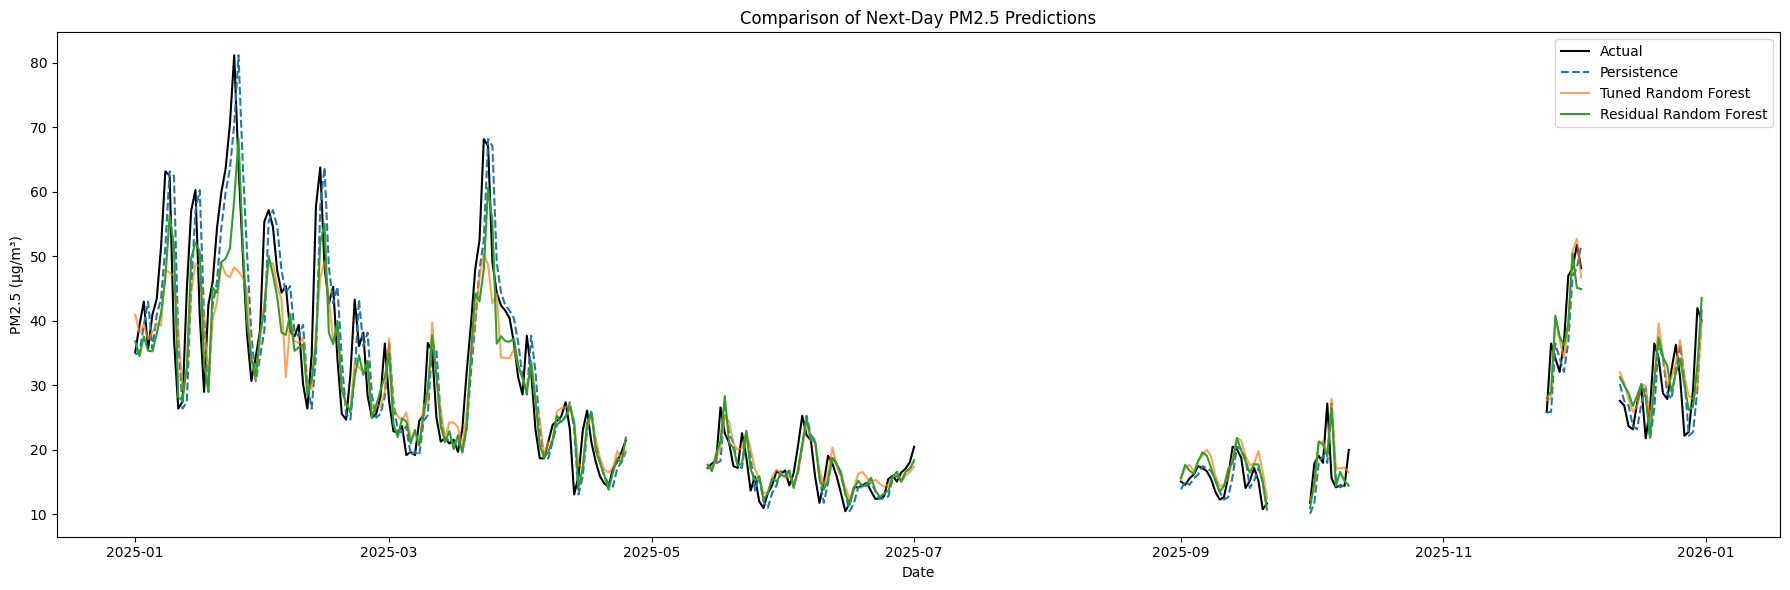

In [ ]:
plot_df = pd.DataFrame({
    "Actual": y_val,
    "Persistence": today_val,
    "Tuned RF": tuned_val_pred,
    "Residual RF": residual_val_pred
}, index=pd.to_datetime(dates_val))

plot_df = plot_df.reindex(
    pd.date_range(
        "2025-01-01",
        "2025-12-31",
        freq="D"
    )
)

plt.figure(figsize=(18, 6))

plt.plot(
    plot_df["Actual"],
    color="black",
    label="Actual"
)

plt.plot(
    plot_df["Persistence"],
    linestyle="--",
    label="Persistence"
)

plt.plot(
    plot_df["Tuned RF"],
    alpha=0.7,
    label="Tuned Random Forest"
)

plt.plot(
    plot_df["Residual RF"],
    label="Residual Random Forest"
)

plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")
plt.title("Comparison of Next-Day PM2.5 Predictions")
plt.legend()
plt.tight_layout()
plt.show()

# **LSTM**

In [2]:
if 'PROJECT_DIR' not in globals():
    from google.colab import drive
    drive.mount('/content/drive')

    from pathlib import Path

    PROJECT_DIR = Path(
        "/content/drive/MyDrive/PM25_Prediction"
    )

    print("Project folder ready:", PROJECT_DIR)
else:
    print("Project folder already established at:", PROJECT_DIR)

Mounted at /content/drive
Project folder ready: /content/drive/MyDrive/PM25_Prediction


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf


# Load the same dataset the baseline and Random Forest use
dataset = np.load(
    PROJECT_DIR / "data/processed/dataset_window7.npz"
)

X_train = dataset["X_train"]
y_train = dataset["y_train"]

X_val = dataset["X_val"]
y_val = dataset["y_val"]

dates_val = pd.to_datetime(dataset["dates_val"])

FEATURES = dataset["features"].tolist()
WINDOW_SIZE = int(dataset["window_size"])
pm25_index = FEATURES.index("pm25")

persistence_pred = X_val[:, -1, pm25_index]

In [4]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

def evaluate_model(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "R2": r2_score(y_true, y_pred)
    }

In [5]:
print("Features:", FEATURES)
print("Training:", X_train.shape)
print("Validation:", X_val.shape)

Features: ['pm25', 'temperature', 'humidity', 'wind_speed', 'precipitation']
Training: (1135, 7, 5)
Validation: (224, 7, 5)


## **Preparing the data for the LSTM**

The LSTM uses the same 7-day windows as the baseline and Random Forest. Each sample holds the
last 7 days of all 5 features.

**The target is PM2.5 on the next day.**

**Scaling:** The features have very different ranges. Neural networks train poorly when inputs have such different sizes, so each feature is standardised to mean 0 and standard deviation 1.

The mean and standard deviation are calculated from the **training years only**, so no information from the 2025
validation data leaks into training.

**The target is scaled the same way.**

**Target choice:**
- `level`: predict tomorrow's PM2.5 directly.
- `delta`: predict the *change* from today (tomorrow − today), then add today's value back.

  *The Random Forest could not predict above the highest value it saw in training, so it
  underpredicted haze spikes. Predicting the change may avoid this, because the forecast can
  go above old peaks.*

All predictions are converted back to µg/m³ with `to_pm25()`, so the RMSE can be compared
directly with other technique.

In [6]:
def prepare_data(target_mode="level"):
    """
    Uses all 5 features.
    target_mode : "level" -> predict PM2.5 tomorrow
                  "delta" -> predict (tomorrow - today), then add today back
    """

    n_features = len(FEATURES)

    # Scale inputs using TRAINING statistics only (no peeking at 2025)
    x_mean = X_train.reshape(-1, n_features).mean(axis=0)
    x_std = X_train.reshape(-1, n_features).std(axis=0) + 1e-8

    X_tr = (X_train - x_mean) / x_std
    X_va = (X_val - x_mean) / x_std

    # Choose what the model predicts
    if target_mode == "delta":
        base_tr = X_train[:, -1, pm25_index]
        base_va = X_val[:, -1, pm25_index]
    else:
        base_tr = np.zeros(len(y_train))
        base_va = np.zeros(len(y_val))

    target_tr = y_train - base_tr
    y_mean = target_tr.mean()
    y_std = target_tr.std()

    y_tr = (target_tr - y_mean) / y_std
    y_va = (y_val - base_va - y_mean) / y_std

    # Turns model output back into PM2.5 (µg/m³)
    def to_pm25(scaled_pred):
        return scaled_pred * y_std + y_mean + base_va

    return X_tr, y_tr, X_va, y_va, to_pm25

## **LSTM V1: default model**

PM2.5 is a time series: today's value depends on the previous days.

**LSTM**
1. reads the 7-day window one day at a time and keeps a *cell state* (memory)
2. its gates decide what to keep, what to forget and what to output
3. it can learn patterns across several days

**V1 - default settings:**
- Input: 7 days × 5 features
- 1 LSTM layer with 32 units
- 1 Dense output neuron (tomorrow's PM2.5, scaled)
- Loss: mean squared error.
- Optimiser: Adam (learning rate 0.001). Batch size 32, 100 epochs.

The random seed is fixed so the result can be reproduced.

In [7]:
def build_lstm(units=32, n_layers=1, dropout=0.0, learning_rate=0.001):

    model = tf.keras.Sequential()
    model.add(tf.keras.Input(shape=(X_train.shape[1], X_train.shape[2])))

    for i in range(n_layers):
        # Every LSTM layer except the last passes the whole sequence on
        model.add(tf.keras.layers.LSTM(
            units,
            return_sequences=(i < n_layers - 1)
        ))
        if dropout > 0:
            model.add(tf.keras.layers.Dropout(dropout))

    model.add(tf.keras.layers.Dense(1))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="mse"
    )
    return model

In [8]:
# ----- V1: default settings -----
tf.keras.utils.set_random_seed(42)

X_tr, y_tr, X_va, y_va, to_pm25 = prepare_data("level")

lstm_v1 = build_lstm()
lstm_v1.summary()

history_v1 = lstm_v1.fit(
    X_tr, y_tr,
    validation_data=(X_va, y_va),   # only watched, not used for training
    epochs=100,
    batch_size=32,
    verbose=0
)

best_epoch = int(np.argmin(history_v1.history["val_loss"])) + 1
print("\nLowest validation loss at epoch:", best_epoch)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,897 (19.13 KB)

 Trainable params: 4,897 (19.13 KB)

 Non-trainable params: 0 (0.00 B)


Lowest validation loss at epoch: 15


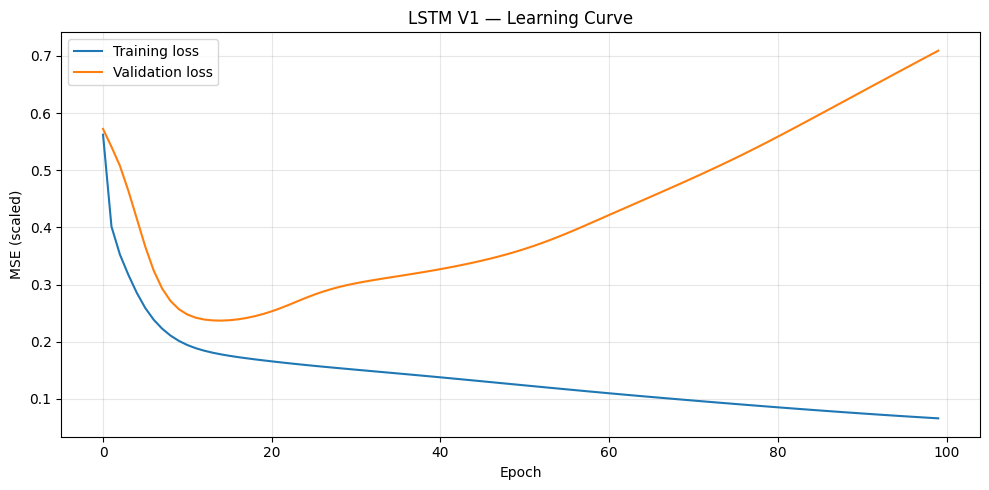

In [9]:
plt.figure(figsize=(10, 5))
plt.plot(history_v1.history["loss"], label="Training loss")
plt.plot(history_v1.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE (scaled)")
plt.title("LSTM V1 — Learning Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Evaluating LSTM V1**

The V1 predictions are converted back to µg/m³ and scored with the same metrics as the other
models (MAE, RMSE, R²), on both the training years and the 2025 validation year.

V1 is then compared with the **persistence baseline** ("tomorrow = today"), which every model
must beat. V1 was trained for a fixed 100 epochs, and the learning curve showed overfitting
after about 15 epochs. So V1 is expected to do much better on training data than on
validation data. This is the "before" result that V2 and V3 improve on.

In [10]:
# ----- Predictions in µg/m³ -----
y_train_pred = lstm_v1.predict(X_tr, verbose=0).ravel() * y_train.std() + y_train.mean()
y_val_pred = to_pm25(lstm_v1.predict(X_va, verbose=0).ravel())

# ----- Training vs validation -----
results = pd.DataFrame(
    [
        evaluate_model(y_train, y_train_pred),
        evaluate_model(y_val, y_val_pred)
    ],
    index=["Training", "Validation"]
)

print(results.round(4))

               MAE    RMSE      R2
Training    1.9730  2.6119  0.9362
Validation  5.8365  8.7083  0.6335


In [13]:
# ----- Compare with persistence -----
comparison = pd.DataFrame({
    "Persistence": evaluate_model(
        y_val, persistence_pred
    ),
    "LSTM V1": evaluate_model(
        y_val, y_val_pred
    )
}).T

print()
print(comparison.round(4))
print()

for metric in ["MAE", "RMSE"]:

    baseline = comparison.loc["Persistence", metric]
    lstm = comparison.loc["LSTM V1", metric]

    improvement = (baseline - lstm) / baseline * 100

    print(f"{metric} improvement: {improvement:.2f}%")


                MAE    RMSE      R2
Persistence  4.3737  6.2417  0.8117
LSTM V1      5.8365  8.7083  0.6335

MAE improvement: -33.45%
RMSE improvement: -39.52%


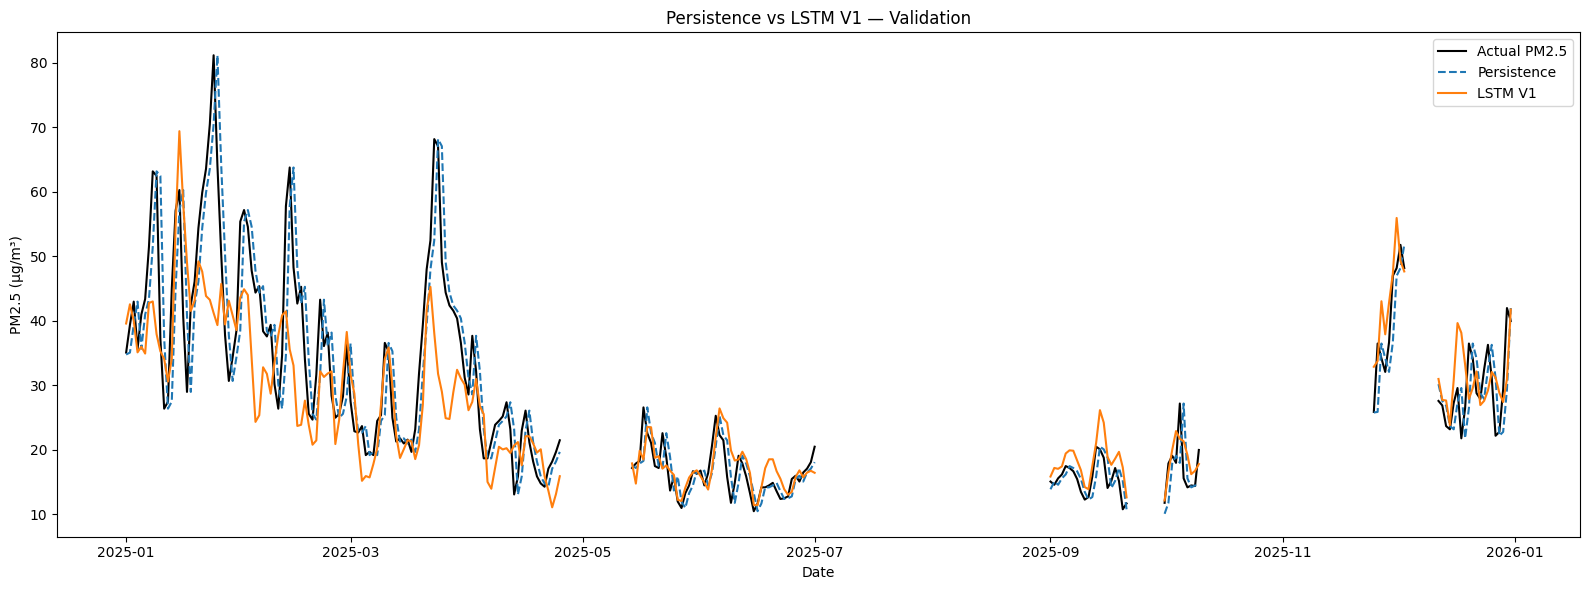

In [14]:
# ----- Plot 2025 -----
plot_df = pd.DataFrame({
    "Actual": y_val,
    "Persistence": persistence_pred,
    "LSTM V1": y_val_pred
}, index=dates_val)

# Missing days show as gaps instead of straight lines
plot_df = plot_df.reindex(
    pd.date_range("2025-01-01", "2025-12-31", freq="D")
)

plt.figure(figsize=(16, 6))

plt.plot(
    plot_df.index,
    plot_df["Actual"],
    color="black",
    label="Actual PM2.5"
)

plt.plot(
    plot_df.index,
    plot_df["Persistence"],
    linestyle="--",
    label="Persistence"
)

plt.plot(
    plot_df.index,
    plot_df["LSTM V1"],
    label="LSTM V1"
)

plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")
plt.title("Persistence vs LSTM V1 — Validation")
plt.legend()
plt.tight_layout()
plt.show()

## **LSTM V2: hyperparameter tuning**

**Early stopping:** From V2 onwards, every model uses
early stopping: training stops when validation loss has not improved for 20 epochs, and the
weights from the best epoch are restored.

Without this, the tuning would mostly measure how
badly each setting overfits after a fixed number of epochs, not which setting is better.

**Several random seeds:** A neural network's result depends on its random starting weights.
With only **224** validation days, one lucky seed can look like an improvement. Each setting is
therefore trained with 3 seeds, and we report the mean RMSE ± its standard deviation. If the
difference between two settings is smaller than this spread, it is not a real difference.

**Tuning one setting at a time:** As with the Random Forest, we change one hyperparameter,
keep the best value, then move on to the next: units → learning rate → batch size → layers.

**Step 1: number of LSTM units** Fewer units may be too simple to learn the pattern; more units can memorise the training years and overfit.

In [15]:
def train_lstm(units=32, n_layers=1, dropout=0.0, learning_rate=0.001,
               batch_size=32, target_mode="level", seeds=(42, 7, 123)):
    """
    Trains the same setting once per seed with early stopping,
    and returns the average scores in µg/m³.
    """

    X_tr, y_tr, X_va, y_va, to_pm25 = prepare_data(target_mode)

    # Needed to turn training predictions back into µg/m³
    base_tr = X_train[:, -1, pm25_index] if target_mode == "delta" else np.zeros(len(y_train))
    y_std = (y_train - base_tr).std()

    train_scores, val_scores, best_epochs, val_preds = [], [], [], []

    for seed in seeds:

        tf.keras.utils.set_random_seed(seed)

        model = build_lstm(units, n_layers, dropout, learning_rate)

        early_stop = tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=20,
            restore_best_weights=True
        )

        history = model.fit(
            X_tr, y_tr,
            validation_data=(X_va, y_va),
            epochs=300,
            batch_size=batch_size,
            callbacks=[early_stop],
            verbose=0
        )

        train_pred = y_train + (model.predict(X_tr, verbose=0).ravel() - y_tr) * y_std
        val_pred = to_pm25(model.predict(X_va, verbose=0).ravel())

        train_scores.append(evaluate_model(y_train, train_pred))
        val_scores.append(evaluate_model(y_val, val_pred))
        best_epochs.append(int(np.argmin(history.history["val_loss"])) + 1)
        val_preds.append(val_pred)

    train_scores = pd.DataFrame(train_scores)
    val_scores = pd.DataFrame(val_scores)

    summary = {
        "train_MAE": train_scores["MAE"].mean(),
        "train_RMSE": train_scores["RMSE"].mean(),
        "val_MAE": val_scores["MAE"].mean(),
        "val_RMSE": val_scores["RMSE"].mean(),
        "val_RMSE_std": val_scores["RMSE"].std(),
        "val_R2": val_scores["R2"].mean(),
        "best_epoch": np.mean(best_epochs)
    }

    # Average prediction over the seeds (used for plots later)
    return summary, np.mean(val_preds, axis=0)

In [16]:
# ----- V2 step 1: number of LSTM units -----
units_results = []

for units in [16, 32, 64, 128]:

    summary, _ = train_lstm(units=units)
    summary = {"units": units, **summary}
    units_results.append(summary)

    print(f"units={units:4d}  val_RMSE={summary['val_RMSE']:.4f} "
          f"± {summary['val_RMSE_std']:.4f}")

units_results = pd.DataFrame(units_results)

print()
print(units_results.round(4).to_string())

best_units = int(units_results.loc[units_results["val_RMSE"].idxmin(), "units"])
print("\nBest number of units:", best_units)

persistence_results = evaluate_model(y_val, X_val[:, -1, pm25_index])

units=  16  val_RMSE=5.5212 ± 0.1261
units=  32  val_RMSE=5.5163 ± 0.4226
units=  64  val_RMSE=5.2779 ± 0.3513
units= 128  val_RMSE=5.3324 ± 0.2635

   units  train_MAE  train_RMSE  val_MAE  val_RMSE  val_RMSE_std  val_R2  best_epoch
0     16     3.1189      4.2926   4.0343    5.5212        0.1261  0.8526     26.3333
1     32     3.1130      4.2898   4.1012    5.5163        0.4226  0.8523     16.6667
2     64     3.1885      4.3704   3.9420    5.2779        0.3513  0.8650     11.3333
3    128     3.1823      4.3759   3.9450    5.3324        0.2635  0.8623      8.6667

Best number of units: 64


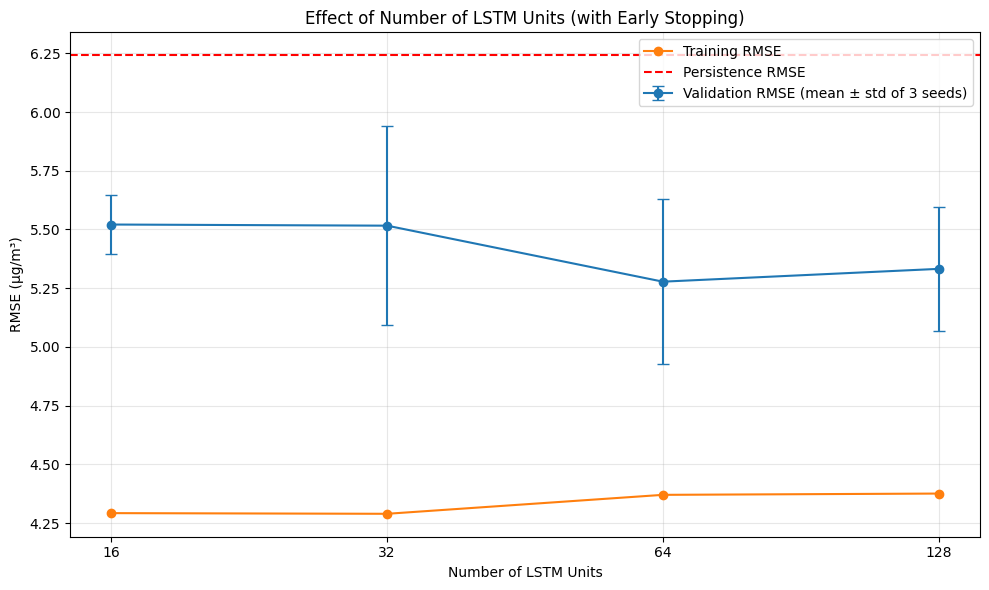

In [17]:
plt.figure(figsize=(10, 6))

plt.errorbar(
    units_results["units"],
    units_results["val_RMSE"],
    yerr=units_results["val_RMSE_std"],
    marker="o",
    capsize=4,
    label="Validation RMSE (mean ± std of 3 seeds)"
)

plt.plot(
    units_results["units"],
    units_results["train_RMSE"],
    marker="o",
    label="Training RMSE"
)

plt.axhline(
    persistence_results["RMSE"],
    color="red",
    linestyle="--",
    label="Persistence RMSE"
)

plt.xscale("log", base=2)
plt.xticks(units_results["units"], units_results["units"])

plt.xlabel("Number of LSTM Units")
plt.ylabel("RMSE (µg/m³)")
plt.title("Effect of Number of LSTM Units (with Early Stopping)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Step 2: learning rate.** The learning rate controls how big a step the optimiser (Adam)
takes when it updates the weights.

- If it is too large, training jumps around and may never
settle at a good solution.

- If it is too small, training is slow and may stop before it reaches a good solution.

We keep the best number of units from step 1 and try 4 learning rates. We also watch `val_RMSE_std`: a good learning rate often makes results more stable
between seeds.

In [18]:
def sweep(param_name, values, fixed_params, log_x=True):
    """
    Trains one LSTM setting per value of `param_name`,
    keeping every other setting fixed, and plots the result.
    """

    rows = []

    for value in values:

        params = {**fixed_params, param_name: value}
        summary, _ = train_lstm(**params)
        rows.append({param_name: value, **summary})

        print(f"{param_name}={value}  val_RMSE={summary['val_RMSE']:.4f} "
              f"± {summary['val_RMSE_std']:.4f}  best_epoch={summary['best_epoch']:.1f}")

    results = pd.DataFrame(rows)

    print()
    print(results.round(4).to_string())

    plt.figure(figsize=(10, 6))

    plt.errorbar(
        results[param_name],
        results["val_RMSE"],
        yerr=results["val_RMSE_std"],
        marker="o",
        capsize=4,
        label="Validation RMSE (mean ± std of 3 seeds)"
    )

    plt.plot(
        results[param_name],
        results["train_RMSE"],
        marker="o",
        label="Training RMSE"
    )

    plt.axhline(
        persistence_results["RMSE"],
        color="red",
        linestyle="--",
        label="Persistence RMSE"
    )

    if log_x:
        plt.xscale("log")
    plt.xticks(results[param_name], results[param_name])

    plt.xlabel(param_name)
    plt.ylabel("RMSE (µg/m³)")
    plt.title(f"Effect of {param_name} (with Early Stopping)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    best_value = results.loc[results["val_RMSE"].idxmin(), param_name]
    print(f"Best {param_name}:", best_value)

    return results, best_value

learning_rate=0.003  val_RMSE=5.1091 ± 0.1470  best_epoch=4.3
learning_rate=0.001  val_RMSE=5.2779 ± 0.3513  best_epoch=11.3
learning_rate=0.0003  val_RMSE=5.2586 ± 0.2072  best_epoch=36.3
learning_rate=0.0001  val_RMSE=5.1826 ± 0.1490  best_epoch=106.3

   learning_rate  train_MAE  train_RMSE  val_MAE  val_RMSE  val_RMSE_std  val_R2  best_epoch
0         0.0030     3.1853      4.4021   3.8557    5.1091        0.1470  0.8738      4.3333
1         0.0010     3.1885      4.3704   3.9420    5.2779        0.3513  0.8650     11.3333
2         0.0003     3.1507      4.3270   3.9382    5.2586        0.2072  0.8662     36.3333
3         0.0001     3.1361      4.3068   3.9037    5.1826        0.1490  0.8701    106.3333


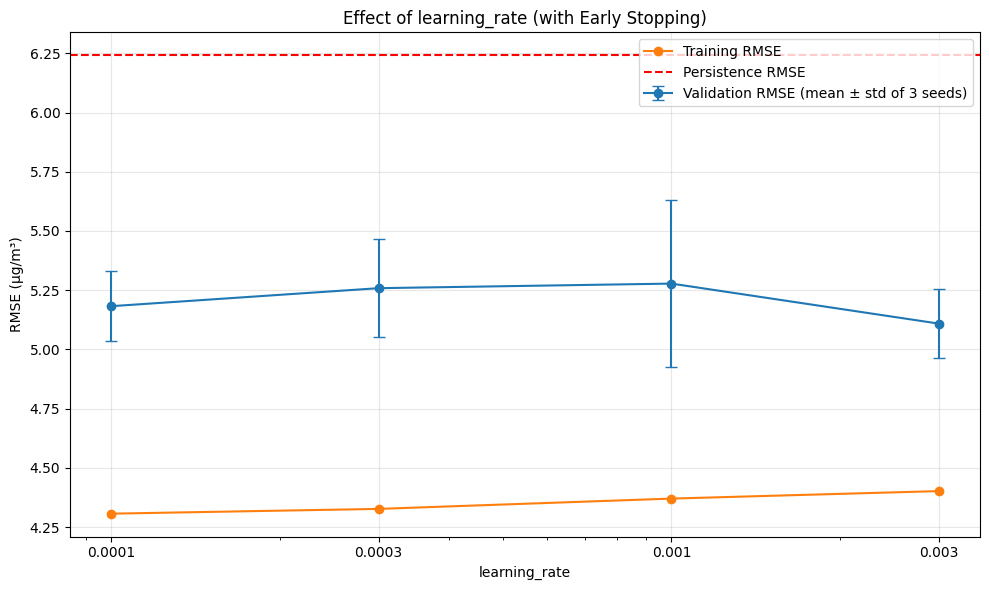

Best learning_rate: 0.003
Best settings so far: {'units': 64, 'learning_rate': 0.003}


In [19]:
# Best settings so far (each step adds its winner)
best_params = {"units": best_units}

# ----- V2 step 2: learning rate -----
lr_results, best_lr = sweep(
    "learning_rate",
    [0.003, 0.001, 0.0003, 0.0001],
    best_params
)

best_params["learning_rate"] = float(best_lr)
print("Best settings so far:", best_params)

**Step 3: batch size.** The batch size is how many samples the model looks at before each
weight update.

- Small batches give more updates per epoch, but each update is noisier.
- Large batches give smoother but fewer updates.

Batch size interacts with the learning rate, so it
is tuned after it.

batch_size=16  val_RMSE=5.1355 ± 0.2004  best_epoch=3.0
batch_size=32  val_RMSE=5.1091 ± 0.1470  best_epoch=4.3
batch_size=64  val_RMSE=5.3087 ± 0.3948  best_epoch=7.0
batch_size=128  val_RMSE=5.2077 ± 0.1686  best_epoch=11.0

   batch_size  train_MAE  train_RMSE  val_MAE  val_RMSE  val_RMSE_std  val_R2  best_epoch
0          16     3.2678      4.4746   3.9419    5.1355        0.2004  0.8724      3.0000
1          32     3.1853      4.4021   3.8557    5.1091        0.1470  0.8738      4.3333
2          64     3.2219      4.3920   3.9731    5.3087        0.3948  0.8633      7.0000
3         128     3.1949      4.3768   3.9505    5.2077        0.1686  0.8688     11.0000


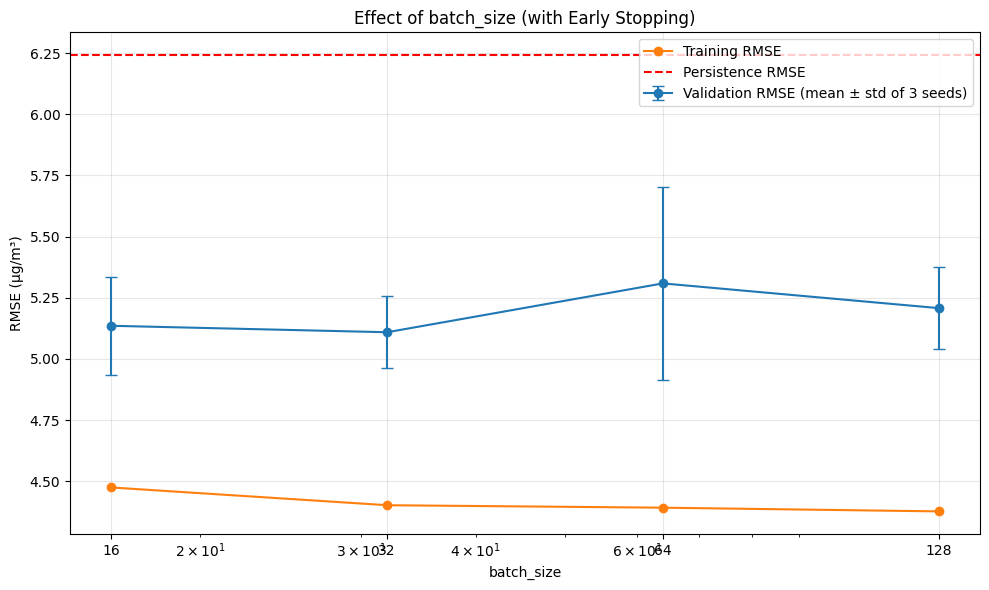

Best batch_size: 32
Best settings so far: {'units': 64, 'learning_rate': 0.003, 'batch_size': 32}


In [20]:
# ----- V2 step 3: batch size -----
batch_results, best_batch = sweep(
    "batch_size",
    [16, 32, 64, 128],
    best_params
)

best_params["batch_size"] = int(best_batch)
print("Best settings so far:", best_params)

**Step 4: number of LSTM layers.** A second LSTM layer can learn more complex patterns over
time, since the first layer passes its whole sequence to the second. But it doubles the
model's size, which can make overfitting worse on a small dataset.

n_layers=1  val_RMSE=5.1091 ± 0.1470  best_epoch=4.3
n_layers=2  val_RMSE=5.4895 ± 0.0388  best_epoch=4.3

   n_layers  train_MAE  train_RMSE  val_MAE  val_RMSE  val_RMSE_std  val_R2  best_epoch
0         1     3.1853      4.4021   3.8557    5.1091        0.1470  0.8738      4.3333
1         2     3.1846      4.3847   4.0671    5.4895        0.0388  0.8543      4.3333


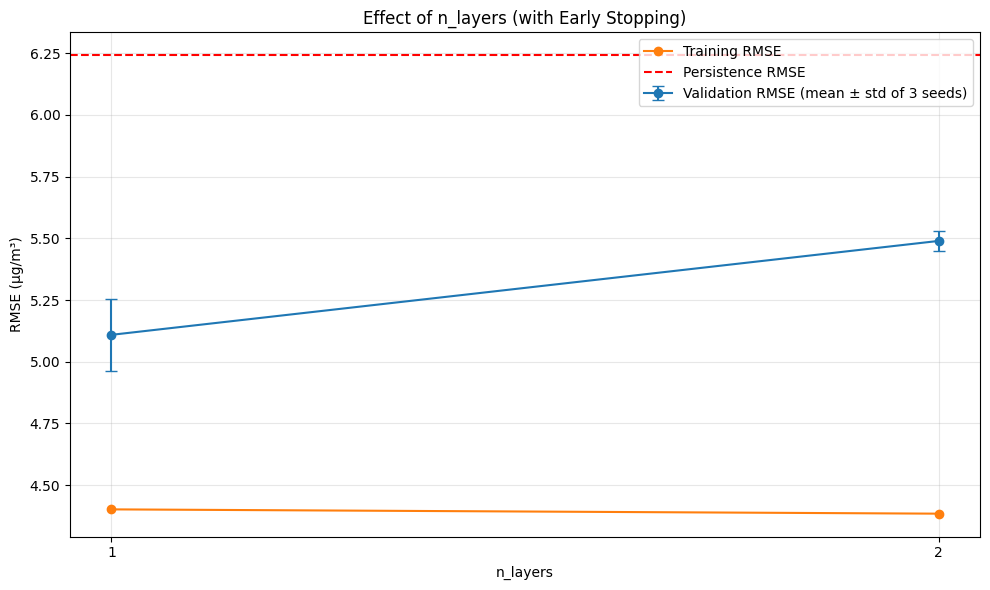

Best n_layers: 1

Final V2 settings: {'units': 64, 'learning_rate': 0.003, 'batch_size': 32, 'n_layers': 1}


In [21]:
# ----- V2 step 4: number of LSTM layers -----
layer_results, best_layers = sweep(
    "n_layers",
    [1, 2],
    best_params,
    log_x=False
)

best_params["n_layers"] = int(best_layers)
print("\nFinal V2 settings:", best_params)

## **LSTM V3: extra techniques**

V2 tuned the model's settings. V3 adds two new techniques on top of the best V2 model.

**Technique 1: predicting the change (residual target).** Instead of predicting tomorrow's
PM2.5 directly, the model predicts the change from today (tomorrow − today). Today's value is
added back to get the forecast. The model starts from "tomorrow = today" and only has to learn
when PM2.5 will rise or fall. The forecast can also go above the highest value seen in training.

target_mode=level  val_RMSE=5.1091 ± 0.1470  best_epoch=4.3
target_mode=delta  val_RMSE=5.1423 ± 0.2912  best_epoch=5.3

  target_mode  train_MAE  train_RMSE  val_MAE  val_RMSE  val_RMSE_std  val_R2  best_epoch
0       level     3.1853      4.4021   3.8557    5.1091        0.1470  0.8738      4.3333
1       delta     3.1372      4.3304   3.7221    5.1423        0.2912  0.8719      5.3333


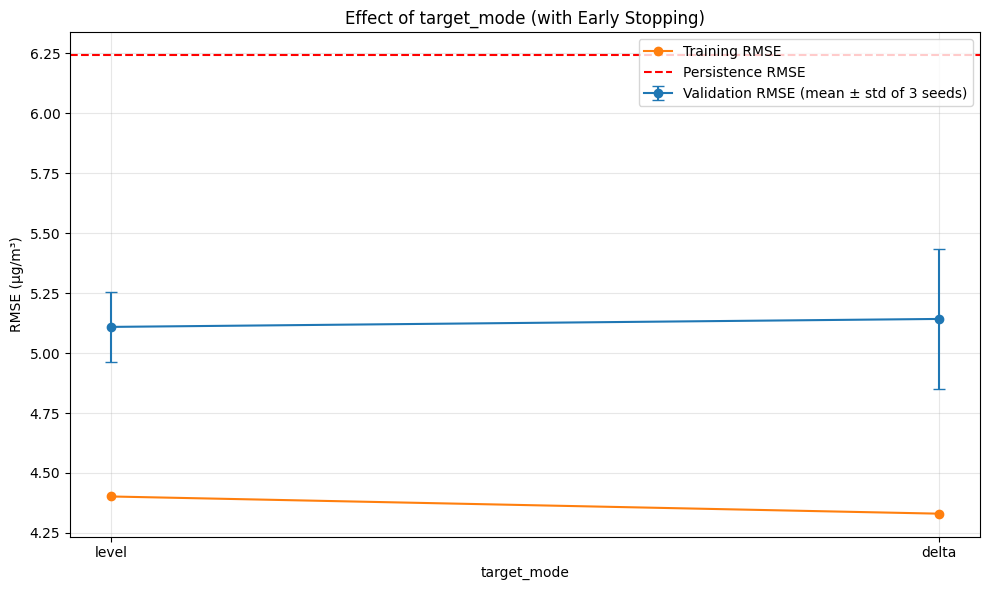

Best target_mode: level
Best settings so far: {'units': 64, 'learning_rate': 0.003, 'batch_size': 32, 'n_layers': 1, 'target_mode': 'level'}


In [22]:
# ----- V3 step 1: level vs delta target -----
target_results, best_target = sweep(
    "target_mode",
    ["level", "delta"],
    best_params,
    log_x=False
)

best_params["target_mode"] = str(best_target)
print("Best settings so far:", best_params)

**Technique 2: dropout.** During training, dropout randomly switches off a fraction of the
LSTM's outputs at each step, so the model cannot rely on a few specific connections. This is
a standard way to reduce overfitting, which was the main problem in V1 and V2.


dropout=0.0  val_RMSE=5.1091 ± 0.1470  best_epoch=4.3
dropout=0.1  val_RMSE=5.0961 ± 0.1063  best_epoch=7.3
dropout=0.2  val_RMSE=5.1297 ± 0.2231  best_epoch=8.0
dropout=0.3  val_RMSE=5.0659 ± 0.2149  best_epoch=8.3

   dropout  train_MAE  train_RMSE  val_MAE  val_RMSE  val_RMSE_std  val_R2  best_epoch
0      0.0     3.1853      4.4021   3.8557    5.1091        0.1470  0.8738      4.3333
1      0.1     3.1143      4.3009   3.8136    5.0961        0.1063  0.8744      7.3333
2      0.2     3.1123      4.3111   3.8360    5.1297        0.2231  0.8727      8.0000
3      0.3     3.1318      4.3348   3.7572    5.0659        0.2149  0.8758      8.3333


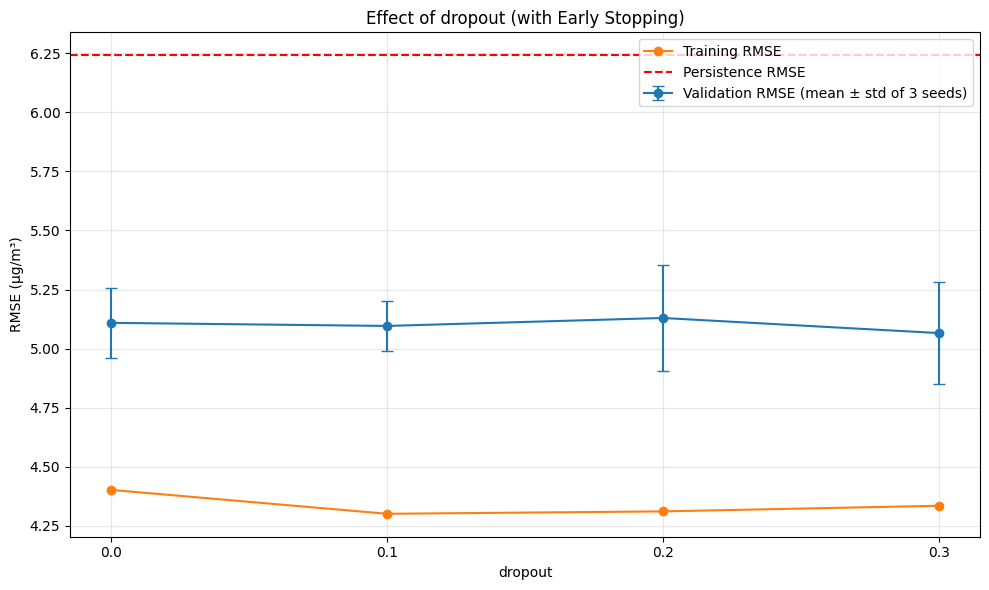

Best dropout: 0.3

Final V3 settings: {'units': 64, 'learning_rate': 0.003, 'batch_size': 32, 'n_layers': 1, 'target_mode': 'level', 'dropout': 0.3}


In [23]:
# ----- V3 step 2: dropout -----
dropout_results, best_dropout = sweep(
    "dropout",
    [0.0, 0.1, 0.2, 0.3],
    best_params,
    log_x=False
)

best_params["dropout"] = float(best_dropout)
print("\nFinal V3 settings:", best_params)

## **LSTM results: V1 → V2 → V3**

The final V2 and V3 models are trained with 3 seeds each, and their predictions are averaged.
The table compares all LSTM versions with persistence on the 2025 validation set, and shows
each model's highest prediction (actual 2025 peak: 81.2 µg/m³).

The error-by-level table splits the validation days by how polluted they were, to show where
the LSTM beats persistence and where it still fails. A positive bias means the model
underpredicts on those days.

In [24]:
# ----- Final V2 and V3 models (3 seeds each, predictions averaged over seeds) -----
v2_params = {k: v for k, v in best_params.items() if k not in ["target_mode", "dropout"]}
v3_params = dict(best_params)

v2_summary, v2_val_pred = train_lstm(**v2_params)
v3_summary, v3_val_pred = train_lstm(**v3_params)

# ----- V1 predictions again (model trained in Block 3) -----
X_tr1, y_tr1, X_va1, y_va1, to_pm25_level = prepare_data("level")
v1_val_pred = to_pm25_level(lstm_v1.predict(X_va1, verbose=0).ravel())

# ----- Summary table: V1 -> V2 -> V3 -----
val_predictions = {
    "Persistence": persistence_pred,
    "LSTM V1 (default, 100 epochs)": v1_val_pred,
    "LSTM V2 (tuned + early stopping)": v2_val_pred,
    "LSTM V3 (+ " + v3_params["target_mode"] + " target, dropout "
        + str(v3_params["dropout"]) + ")": v3_val_pred
}

lstm_summary = pd.DataFrame(
    {name: evaluate_model(y_val, pred) for name, pred in val_predictions.items()}
).T

lstm_summary["RMSE vs persistence (%)"] = (
    (persistence_results["RMSE"] - lstm_summary["RMSE"])
    / persistence_results["RMSE"] * 100
)

lstm_summary["Max prediction"] = [pred.max() for pred in val_predictions.values()]

print("Actual maximum in 2025:", y_val.max())
print("Training maximum:", y_train.max())
print()
print(lstm_summary.astype(float).round(4).to_string())
print()
print("Mean RMSE of the 3 single-seed models:")
print(f"  V2: {v2_summary['val_RMSE']:.4f} ± {v2_summary['val_RMSE_std']:.4f}")
print(f"  V3: {v3_summary['val_RMSE']:.4f} ± {v3_summary['val_RMSE_std']:.4f}")

# ----- Error by pollution level (where does the LSTM win or lose?) -----
error_analysis = pd.DataFrame({
    "actual": y_val,
    "persistence": persistence_pred,
    "lstm_v3": v3_val_pred
})

error_analysis["pollution_level"] = pd.cut(
    error_analysis["actual"],
    bins=[0, 20, 35, 50, np.inf],
    labels=["0-20", "20-35", "35-50", "50+"],
    include_lowest=True
)

for model in ["persistence", "lstm_v3"]:
    error_analysis[f"{model}_residual"] = error_analysis["actual"] - error_analysis[model]
    error_analysis[f"{model}_abs_error"] = error_analysis[f"{model}_residual"].abs()

level_summary = (
    error_analysis
    .groupby("pollution_level", observed=True)
    .agg(
        samples=("actual", "size"),
        persistence_MAE=("persistence_abs_error", "mean"),
        lstm_MAE=("lstm_v3_abs_error", "mean"),
        persistence_bias=("persistence_residual", "mean"),
        lstm_bias=("lstm_v3_residual", "mean")
    )
)

print()
print(level_summary.round(3).to_string())

Actual maximum in 2025: 81.2
Training maximum: 70.8

                                          MAE    RMSE      R2  RMSE vs persistence (%)  Max prediction
Persistence                            4.3737  6.2417  0.8117                   0.0000         81.2000
LSTM V1 (default, 100 epochs)          5.8365  8.7083  0.6335                 -39.5172         69.4273
LSTM V2 (tuned + early stopping)       3.8011  5.0311  0.8777                  19.3956         63.5844
LSTM V3 (+ level target, dropout 0.3)  3.7059  4.9543  0.8814                  20.6262         63.9850

Mean RMSE of the 3 single-seed models:
  V2: 5.1091 ± 0.1470
  V3: 5.0659 ± 0.2149

                 samples  persistence_MAE  lstm_MAE  persistence_bias  lstm_bias
pollution_level                                                                 
0-20                  83            2.027     2.102            -0.460     -1.235
20-35                 74            4.253     3.599            -0.836     -0.814
35-50                 4

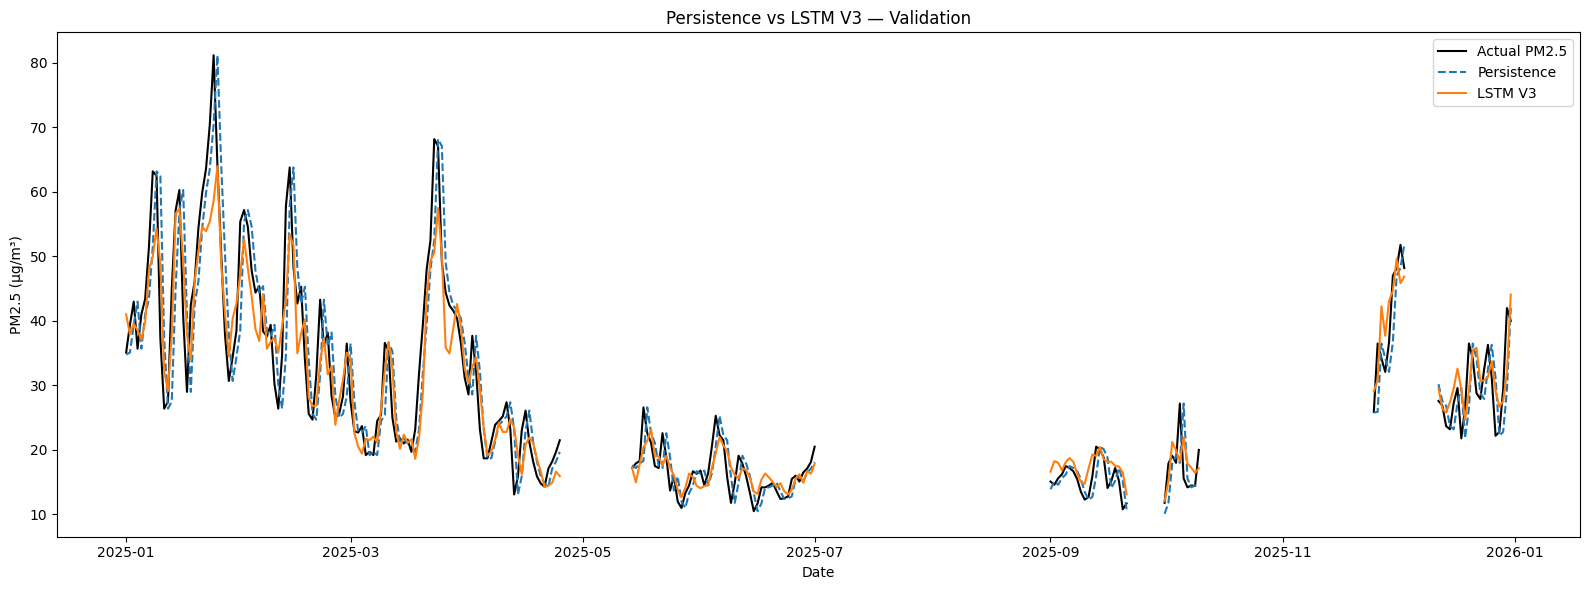

In [25]:
# ----- Plot 2025 -----
plot_df = pd.DataFrame({
    "Actual": y_val,
    "Persistence": persistence_pred,
    "LSTM V3": v3_val_pred
}, index=dates_val)

plot_df = plot_df.reindex(pd.date_range("2025-01-01", "2025-12-31", freq="D"))

plt.figure(figsize=(16, 6))
plt.plot(plot_df.index, plot_df["Actual"], color="black", label="Actual PM2.5")
plt.plot(plot_df.index, plot_df["Persistence"], linestyle="--", label="Persistence")
plt.plot(plot_df.index, plot_df["LSTM V3"], label="LSTM V3")
plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")
plt.title("Persistence vs LSTM V3 — Validation")
plt.legend()
plt.tight_layout()
plt.show()

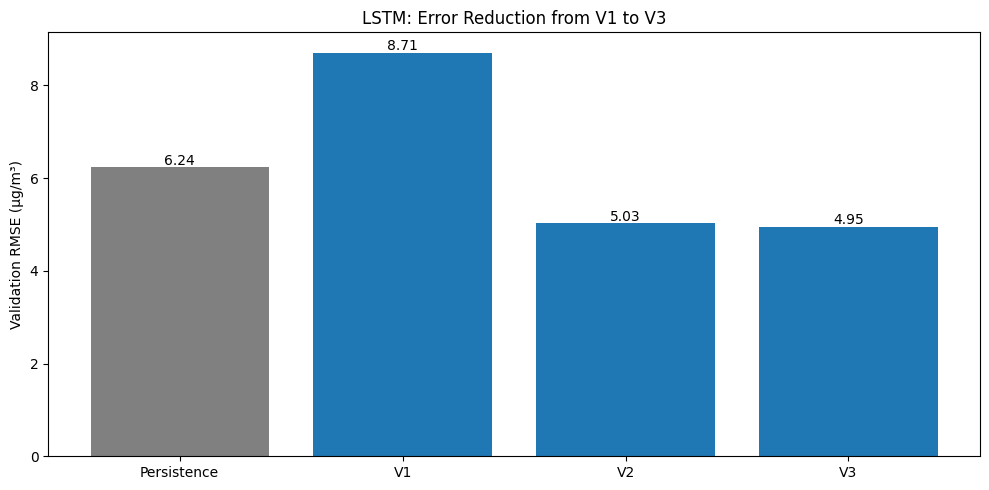

In [26]:
# ----- Error-reduction chart for the slides -----
plt.figure(figsize=(10, 5))
names = ["Persistence", "V1", "V2", "V3"]
plt.bar(names, lstm_summary["RMSE"].values,
        color=["grey", "tab:blue", "tab:blue", "tab:blue"])
for i, v in enumerate(lstm_summary["RMSE"].values):
    plt.text(i, v + 0.05, f"{v:.2f}", ha="center")
plt.ylabel("Validation RMSE (µg/m³)")
plt.title("LSTM: Error Reduction from V1 to V3")
plt.tight_layout()
plt.show()

In [27]:
# ----- Save V3 predictions for the ensemble -----
output = PROJECT_DIR / "experiments/lstm_v3_val_pred.npy"
output.parent.mkdir(parents=True, exist_ok=True)
np.save(output, v3_val_pred)
print("Saved:", output)

Saved: /content/drive/MyDrive/PM25_Prediction/experiments/lstm_v3_val_pred.npy
